# DFT — quatro versões

Neste Notebook implementamos a Transformada Discreta de Fourier (DFT) e sua inversa (IDFT) de quatro formas:

1. **Sinal** — a soma da definição, amostra por amostra
2. **Base** — produto interno do sinal com cada exponencial complexa da base de Fourier
3. **Matriz** — multiplicação matriz-vetor $\mathbf{X} = \mathbf{W}\mathbf{x}$
4. **FFT** — Cooley-Tukey radix-2 com dizimação no tempo (DIT)

$$
X[k] = \sum_{n=0}^{N-1} x[n]\, e^{-j\frac{2\pi}{N}kn}
\qquad
x[n] = \frac{1}{N}\sum_{k=0}^{N-1} X[k]\, e^{+j\frac{2\pi}{N}kn}
$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import sys
import time

In [2]:
'''
Choose your Lib path
'''

try:
    from google.colab import drive

    drive.mount('/content/drive')
    # Google Colab
    LIB_PATH = '/content/drive/MyDrive/UFG/01_teaching/'

except ImportError:
    # Repositorio local: assets/lib/ fica dois niveis acima deste notebook
    LIB_PATH = os.path.abspath('../../')

sys.path.append(LIB_PATH)

In [3]:
from lib.myPlotLib import *
from lib.myAudioProcessingLib import *
from lib.mySignalProcessingLib import SIGNALgenerate

In [4]:
# Definição de diretórios
SOUND_PATH = os.path.join(LIB_PATH, 'sounds') # Pasta de arquivos de som
SOUND_FILE = 'train.wav' # Sinal de entrada

In [5]:
# Carregamos o sinal
x, fs = audioread(os.path.join(SOUND_PATH, SOUND_FILE))

In [6]:
print(x.shape, fs)

(12880,) 8192


In [7]:
play(x, fs)

In [8]:
def COMPLEXmagnitude(z, version='sqrt'):
    if version == 'sqrt':
        '''
        Legnth of z
        '''
        mag = np.sqrt(z.real**2 + z.imag**2)
    elif version == 'abs':
        '''
        |z|
        '''
        mag = np.abs(z)
        
    return mag

def COMPLEXphase(z, version='arctan2', units='rad'):
    if version == 'arctan':
        '''
        arctan
        '''
        phi = np.arctan(z.imag / z.real) # so 1o e 4o quadrantes
    elif version == 'arctan2':
        '''
        arctan2
        '''
        phi = np.arctan2(z.imag, z.real)
    else:
        '''
        angle
        '''
        phi = np.angle(z)
    
    if units == 'deg': # graus
        '''
        rad2deg
        '''
        return phi * 180 / np.pi
        
    return phi

O produto externo $\mathbf{n}\,\mathbf{n}^T$ gera todos os produtos $kn$ de uma vez — é o expoente da matriz da DFT:
$W_{kn} = e^{-j\frac{2\pi}{N}kn}$.

In [9]:
N = 5
n = np.arange(N)[:, np.newaxis] # column vector

A = n @ n.T
print(A)

[[ 0  0  0  0  0]
 [ 0  1  2  3  4]
 [ 0  2  4  6  8]
 [ 0  3  6  9 12]
 [ 0  4  8 12 16]]


In [10]:
def myDFT(x, version='fft'):
    x = np.asarray(x, dtype=complex)
    N = len(x)
    n = np.arange(N)

    if version == 'signal':
        '''
        Signal interpretation
        '''
        X = np.zeros(N, dtype=complex)
        for k in range(N):
            for m in range(N):
                X[k] += x[m] * np.exp(-2j * np.pi * k * m / N)
    
    elif version == 'basis':
        '''
        Basis expansion
        '''
        X = np.zeros(N, dtype=complex)
        for k in range(N):
            e_k  = np.exp(2j * np.pi * k * n / N) # k-esimo vetor da base
            X[k] = np.vdot(e_k, x)                # <x, e_k> = sum x[n] conj(e_k[n])
    
    elif version == 'matrix':
        '''
        Matrix-vector multiplication
        '''
        nk = n[:, np.newaxis] @ n[np.newaxis, :] # produto externo k n
        W  = np.exp(-2j * np.pi * nk / N)        # matriz da DFT
        X  = W @ x
    
    elif version == 'fft':
        '''
        Cooley-Tukey radix-2 DIT FFT
        '''
        if not np.log2(N).is_integer():
            raise ValueError('Signal length must be a power of 2')
        if N == 1:
            return x.copy()
        if N == 2:
            return np.array([x[0] + x[1], x[0] - x[1]])
        else:
            Xe = myDFT(x[0::2], version='fft') # amostras pares
            Xo = myDFT(x[1::2], version='fft') # amostras impares
            basis = np.exp(-2j * np.pi * n / N) # fatores de giro (twiddle)
            return np.append(Xe + basis[0:N//2] * Xo,
                             Xe - basis[0:N//2] * Xo)
        
    else:
        '''
        Numpy
        '''
        X = np.fft.fft(x)
    
    return X

A IDFT é a mesma operação com o sinal do expoente trocado e o fator $1/N$. Na versão FFT usamos a identidade
$\mathrm{IDFT}\{X\} = \frac{1}{N}\,\overline{\mathrm{DFT}\{\overline{X}\}}$, que reaproveita o `myDFT`.

Como os sinais deste notebook são reais, devolvemos só a parte real — a imaginária é erro de arredondamento
(da ordem de $10^{-13}$).

In [11]:
def myIDFT(X, version='ifft'):
    X = np.asarray(X, dtype=complex)
    N = len(X)
    k = np.arange(N)

    if version == 'signal':
        '''
        Signal interpretation
        '''
        x = np.zeros(N, dtype=complex)
        for m in range(N):
            for kk in range(N):
                x[m] += X[kk] * np.exp(2j * np.pi * kk * m / N)
        x /= N
    
    elif version == 'basis':
        '''
        Basis expansion
        '''
        x = np.zeros(N, dtype=complex)
        for kk in range(N):
            e_k = np.exp(2j * np.pi * kk * k / N) # k-esimo vetor da base
            x  += X[kk] * e_k                     # soma ponderada da base
        x /= N
    
    elif version == 'matrix':
        '''
        Matrix-vector multiplication
        '''
        nk = k[:, np.newaxis] @ k[np.newaxis, :]
        W  = np.exp(-2j * np.pi * nk / N)
        x  = W.conj().T @ X / N # W^-1 = W^H / N
    
    elif version == 'fft':
        '''
        Cooley-Tukey radix-2 DIT FFT
        '''
        x = np.conj(myDFT(np.conj(X), version='fft')) / N
        
    else:
        '''
        Numpy
        '''
        x = np.fft.ifft(X)
    
    return x.real

### v1 — notação "Signal" (slide): um exemplo à mão

Antes do som, um sinal pequeno que dá para calcular no papel: $x = [1, 2, 3, 4]$, $N = 4$.

Com $N = 4$, o fator $e^{-j\frac{2\pi}{4}nk} = (-j)^{nk}$ só assume os valores $1, -j, -1, j$:

| $k$ | $X[k] = \sum_n x[n](-j)^{nk}$ | resultado |
|---|---|---|
| 0 | $1 + 2 + 3 + 4$ | $10$ |
| 1 | $1 + 2(-j) + 3(-1) + 4(j)$ | $-2 + 2j$ |
| 2 | $1 + 2(-1) + 3(1) + 4(-1)$ | $-2$ |
| 3 | $1 + 2(j) + 3(-1) + 4(-j)$ | $-2 - 2j$ |

$X[0]$ é sempre a **soma** das amostras (frequência zero = valor médio × $N$).
E $X[3] = \overline{X[1]}$: como $x$ é real, o espectro tem simetria conjugada.

In [12]:
x_mao = np.array([1, 2, 3, 4])
X_mao = myDFT(x_mao, 'signal')
print("analise  X[k] =", np.round(X_mao, 10))
print("esperado      = [10, -2+2j, -2, -2-2j]")
print("sintese  x[n] =", np.round(myIDFT(X_mao, 'signal'), 10))

analise  X[k] = [10.+0.j -2.+2.j -2.-0.j -2.-2.j]
esperado      = [10, -2+2j, -2, -2-2j]
sintese  x[n] = [1. 2. 3. 4.]


In [13]:
y = x[:1024]
play(y, fs)

1024 amostras a $f_s = 8192$ Hz são só $1024/8192 = 0{,}125$ s de som — quase um estalo.
O som inteiro do trem é reconstruído pela v1 mais adiante, na síntese.

In [14]:
Y1 = myDFT(y, 'signal')
# print(Y1) # DFT de y

In [15]:
print(x.dtype, Y1.dtype, len(y), len(Y1))

float64 complex128 1024 1024


In [16]:
Y2 = myDFT(y, 'basis')

In [17]:
Y3 = myDFT(y, 'matrix')

In [18]:
Y4 = myDFT(y, 'fft')

In [19]:
Y5 = myDFT(y, 'numpy')

### As quatro versões dão o mesmo resultado? E quanto custam?

As três primeiras fazem $N^2$ operações; a FFT faz $N\log_2 N$ — para $N = 1024$, cerca de 100× menos.

In [20]:
for name, Yk in [('signal', Y1), ('basis', Y2), ('matrix', Y3), ('fft', Y4)]:
    print(f"{name:>7}: igual ao numpy? {np.allclose(Yk, Y5)}  "
          f"erro max = {np.max(np.abs(Yk - Y5)):.2e}")

print()
for version in ['signal', 'basis', 'matrix', 'fft', 'numpy']:
    t0 = time.perf_counter()
    myDFT(y, version)
    print(f"{version:>7}: {1e3 * (time.perf_counter() - t0):9.2f} ms")

 signal: igual ao numpy? True  erro max = 1.19e-11
  basis: igual ao numpy? True  erro max = 1.19e-11
 matrix: igual ao numpy? True  erro max = 1.06e-11
    fft: igual ao numpy? True  erro max = 2.84e-14



 signal:    618.95 ms
  basis:     44.42 ms
 matrix:     30.28 ms
    fft:      8.81 ms
  numpy:      0.07 ms


### Por que a versão "base" funciona: a base de Fourier é ortogonal

Os $N$ vetores $\mathbf{e}_k[n] = e^{j\frac{2\pi}{N}kn}$ são ortogonais entre si e têm norma² igual a $N$:

$$
\langle \mathbf{e}_k, \mathbf{e}_l \rangle = \sum_{n=0}^{N-1} e^{j\frac{2\pi}{N}(k-l)n} =
\begin{cases} N, & k = l \\ 0, & k \neq l \end{cases}
\qquad\Longleftrightarrow\qquad \mathbf{W}\mathbf{W}^H = N\,\mathbf{I}
$$

Por isso $X[k] = \langle \mathbf{x}, \mathbf{e}_k \rangle$ é a "quantidade" de $\mathbf{e}_k$ dentro de $\mathbf{x}$, e
$\mathbf{x} = \frac{1}{N}\sum_k X[k]\,\mathbf{e}_k$ o remonta — e por isso $\mathbf{W}^{-1} = \mathbf{W}^H/N$ na `myIDFT`.

Consequência direta, o **teorema de Parseval**: a energia é a mesma nos dois domínios,
$\sum_n |x[n]|^2 = \frac{1}{N}\sum_k |X[k]|^2$.

In [21]:
N = 16
n = np.arange(N)
W = np.exp(-2j * np.pi * n[:, np.newaxis] * n[np.newaxis, :] / N)

print("W W^H = N I ?", np.allclose(W @ W.conj().T, N * np.eye(N)))
print("<e_3, e_3> =", np.round(np.vdot(W[3].conj(), W[3].conj()), 10))
print("<e_3, e_5> =", np.round(np.vdot(W[3].conj(), W[5].conj()), 10))

E_tempo = np.sum(y**2)
E_freq  = np.sum(COMPLEXmagnitude(Y4)**2) / len(Y4)
print(f"\nParseval no trem: energia no tempo = {E_tempo:.6f}, na frequencia = {E_freq:.6f}")

W W^H = N I ? True
<e_3, e_3> = (16+0j)
<e_3, e_5> = (-0+0j)

Parseval no trem: energia no tempo = 30.264588, na frequencia = 30.264588


### Quanto a FFT economiza

As versões sinal, base e matriz fazem $N^2$ multiplicações complexas. A FFT divide o problema ao meio
$\log_2 N$ vezes, com $N$ operações em cada nível: $N\log_2 N$. Medindo o tempo para tamanhos crescentes:

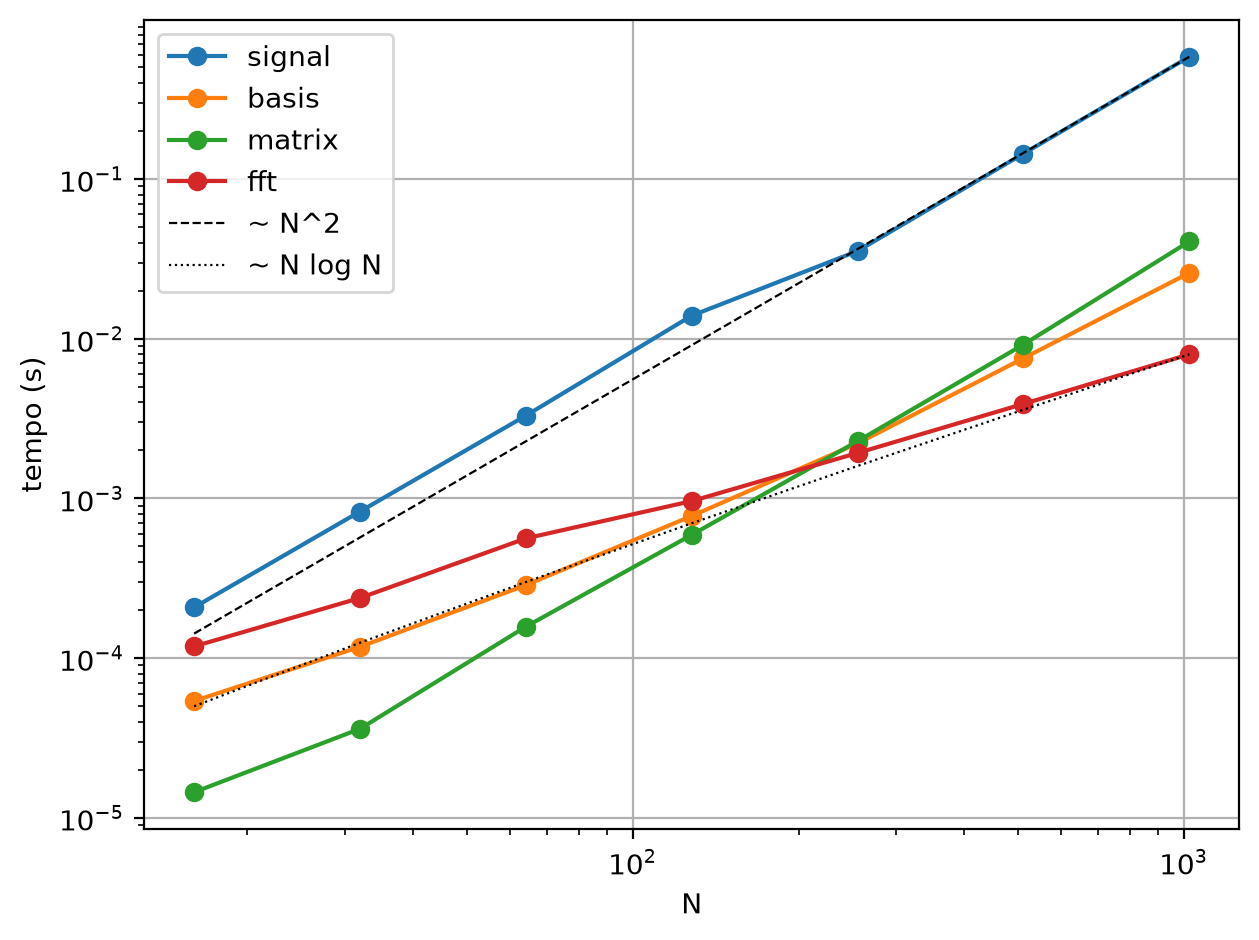

N = 1024 -> N^2 / (N log2 N) = 102x menos operacoes na FFT
medido: signal / fft = 73x


In [22]:
def tempo(version, s, repeticoes=3):
    melhor = np.inf
    for _ in range(repeticoes):
        t0 = time.perf_counter()
        myDFT(s, version)
        melhor = min(melhor, time.perf_counter() - t0)
    return melhor

Ns = 2 ** np.arange(4, 11) # 16 ... 1024
versoes = ['signal', 'basis', 'matrix', 'fft']
tempos = {v: [tempo(v, x[:Nk], 1 if (v == 'signal' and Nk >= 512) else 3) for Nk in Ns] for v in versoes}

fig, ax = plt.subplots()
for v in versoes:
    ax.loglog(Ns, tempos[v], 'o-', label=v)
ax.loglog(Ns, tempos['signal'][-1] * (Ns / Ns[-1])**2, 'k--', linewidth=0.8, label='~ N^2')
ax.loglog(Ns, tempos['fft'][-1] * (Ns*np.log2(Ns)) / (Ns[-1]*np.log2(Ns[-1])), 'k:', linewidth=0.8, label='~ N log N')
ax.set_xlabel('N')
ax.set_ylabel('tempo (s)')
ax.legend()
figureFormat(ax, fig, tight=True)
plt.show()

print(f"N = 1024 -> N^2 / (N log2 N) = {1024**2 / (1024*10):.0f}x menos operacoes na FFT")
print(f"medido: signal / fft = {tempos['signal'][-1] / tempos['fft'][-1]:.0f}x")

A versão `signal` tem a mesma conta da `matrix`, mas paga o laço duplo do Python; a `matrix` delega o $N^2$ ao
BLAS e fica rápida para $N$ pequeno, mas cresce como $N^2$ (e ocupa $N^2$ números de memória — com $N = 2^{16}$ seriam
64 GB). A nossa FFT recursiva cresce como $N\log N$; a do numpy é a mesma ideia, em C.

A FFT radix-2 exige $N$ potência de 2:

In [23]:
try:
    myDFT(x[:1000], 'fft')
except ValueError as erro:
    print("myDFT(x[:1000], 'fft') ->", erro)

# Saida usual: completar com zeros (zero-padding) ate a proxima potencia de 2
s = x[:1000]
Npad = 2 ** int(np.ceil(np.log2(len(s))))
S_pad = myDFT(np.append(s, np.zeros(Npad - len(s))), 'fft')
print(f"com zero-padding para N = {Npad}: igual a np.fft.fft(s, {Npad})? {np.allclose(S_pad, np.fft.fft(s, Npad))}")

myDFT(x[:1000], 'fft') -> Signal length must be a power of 2
com zero-padding para N = 1024: igual a np.fft.fft(s, 1024)? True


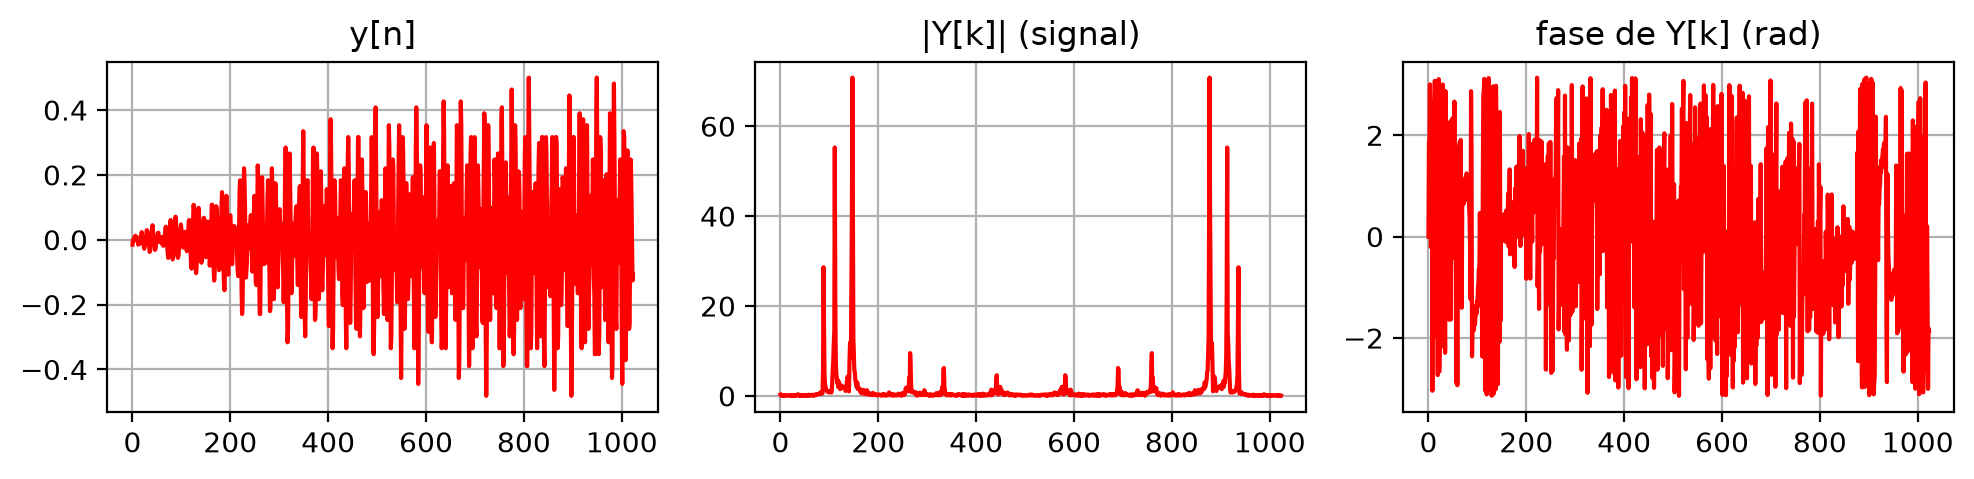

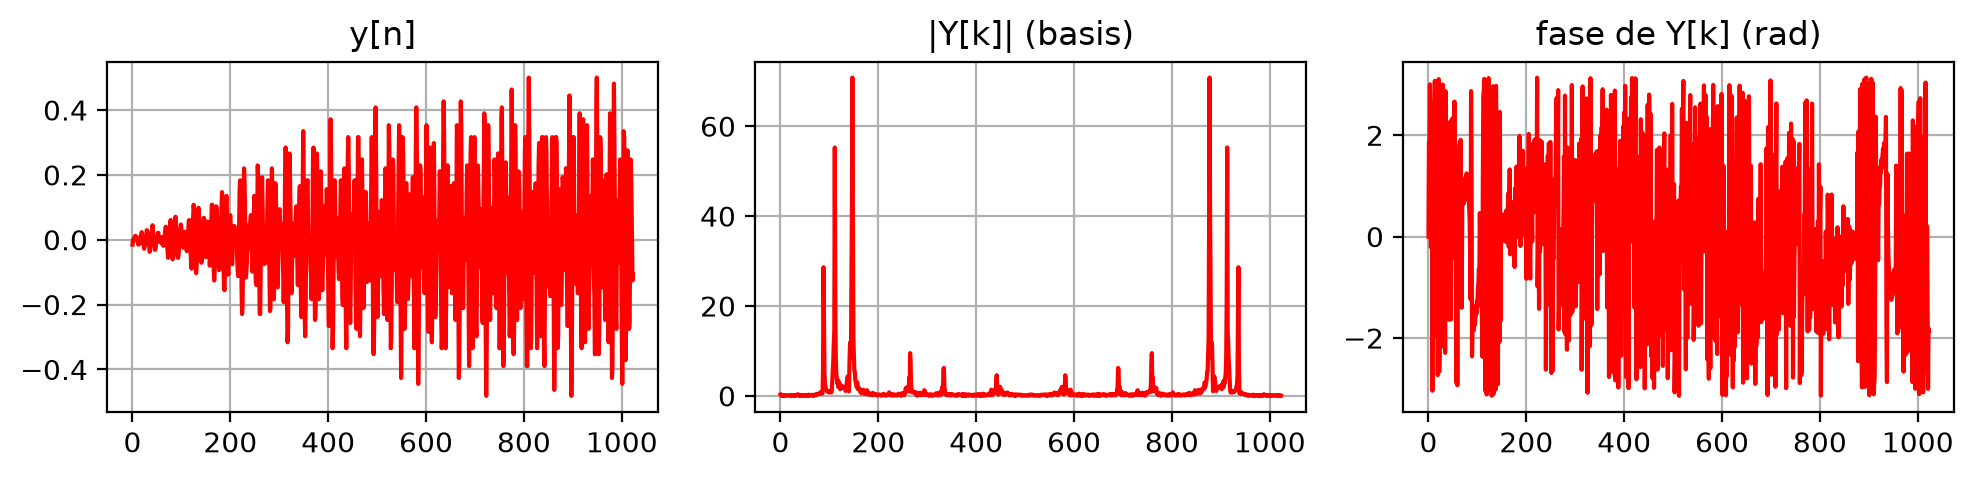

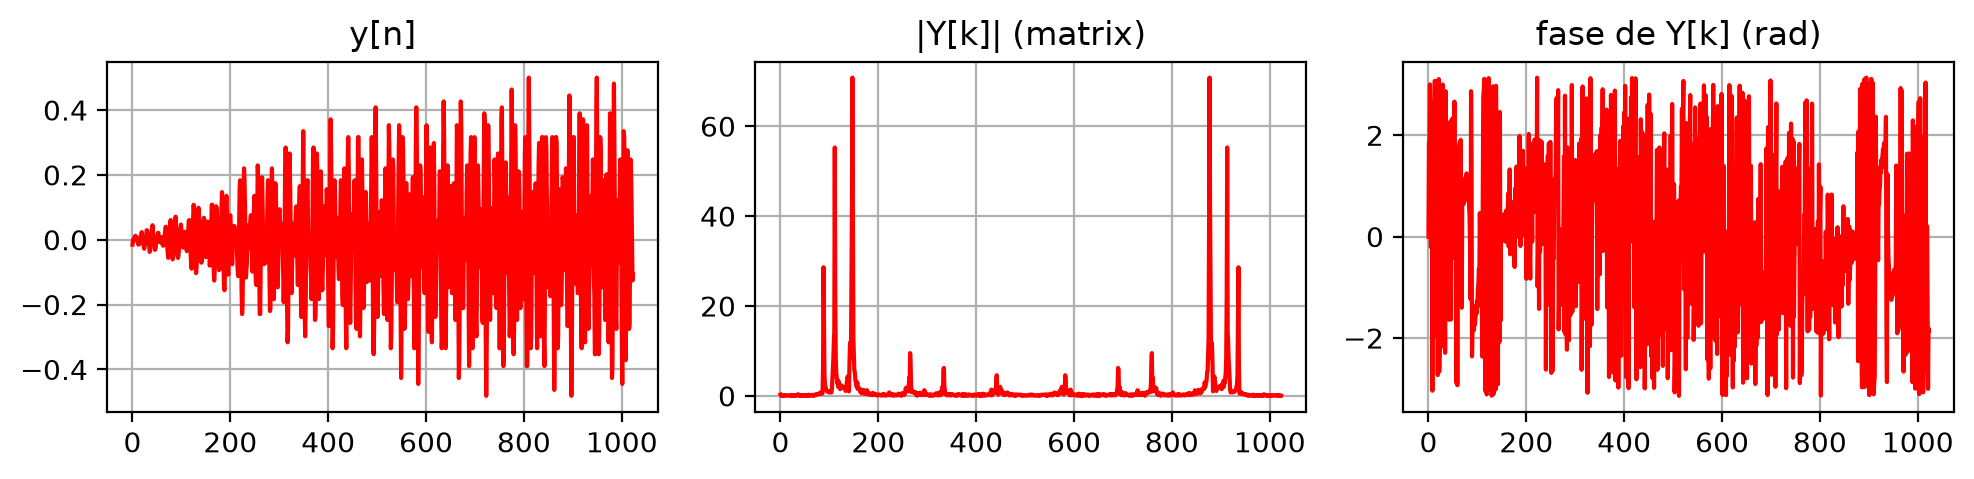

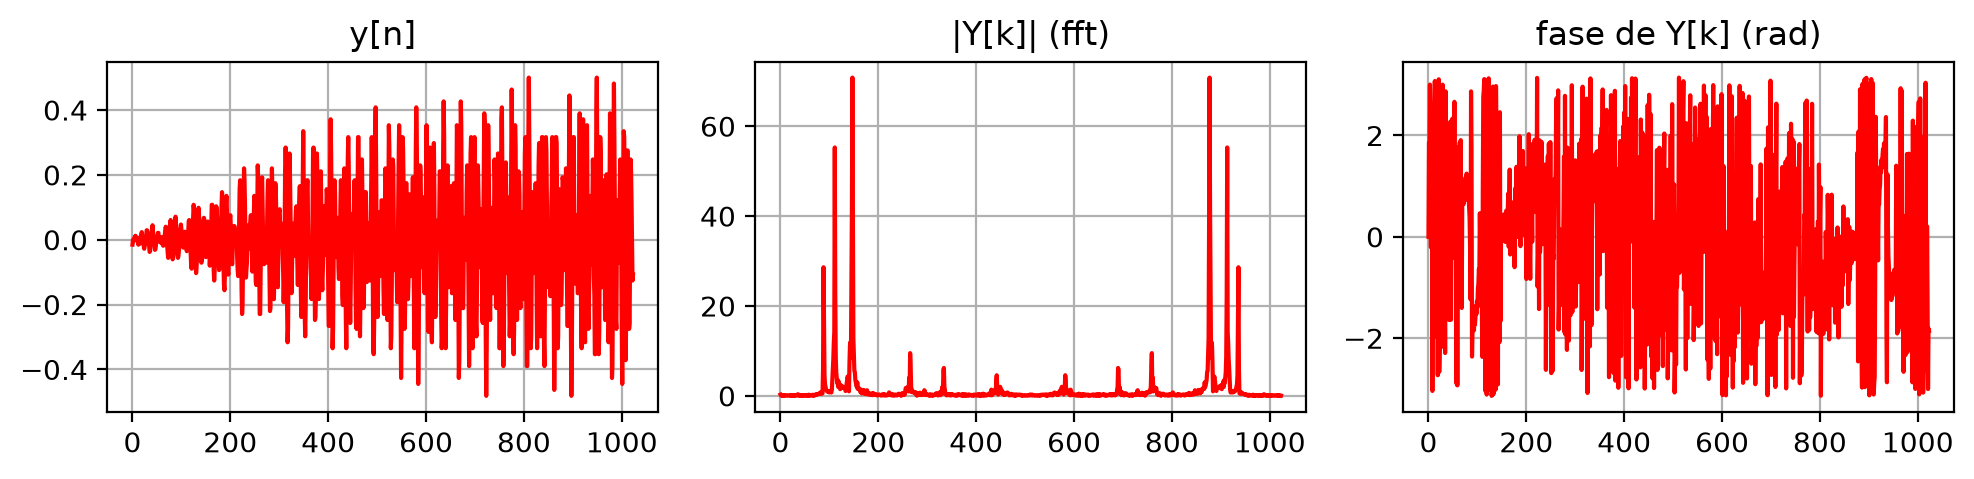

In [24]:
Y1mag = COMPLEXmagnitude(Y1) # Modulo da DFT
Y1pha = COMPLEXphase(Y1) # Fase da DFT

Y2mag = COMPLEXmagnitude(Y2) # Modulo da DFT
Y2pha = COMPLEXphase(Y2) # Fase da DFT

Y3mag = COMPLEXmagnitude(Y3) # Modulo da DFT
Y3pha = COMPLEXphase(Y3) # Fase da DFT

Y4mag = COMPLEXmagnitude(Y4) # Modulo da DFT
Y4pha = COMPLEXphase(Y4) # Fase da DFT

for title, Ymag, Ypha in [('signal', Y1mag, Y1pha), ('basis', Y2mag, Y2pha),
                          ('matrix', Y3mag, Y3pha), ('fft', Y4mag, Y4pha)]:
    fig, ax = plt.subplots(1, 3, figsize=(10, 2.5))
    ax[0].plot(y, 'r')
    ax[0].set_title('y[n]')
    ax[1].plot(Ymag, 'r')
    ax[1].set_title(f'|Y[k]| ({title})')
    ax[2].plot(Ypha, 'r')
    ax[2].set_title('fase de Y[k] (rad)')
    figureFormat(ax, fig, tight=True)
    plt.show()

## Synthesis (signal reconstruction)

float64
 signal: reconstrucao perfeita? True  erro max = 8.24e-14
  basis: reconstrucao perfeita? True  erro max = 8.23e-14
 matrix: reconstrucao perfeita? True  erro max = 9.02e-14
    fft: reconstrucao perfeita? True  erro max = 1.67e-16


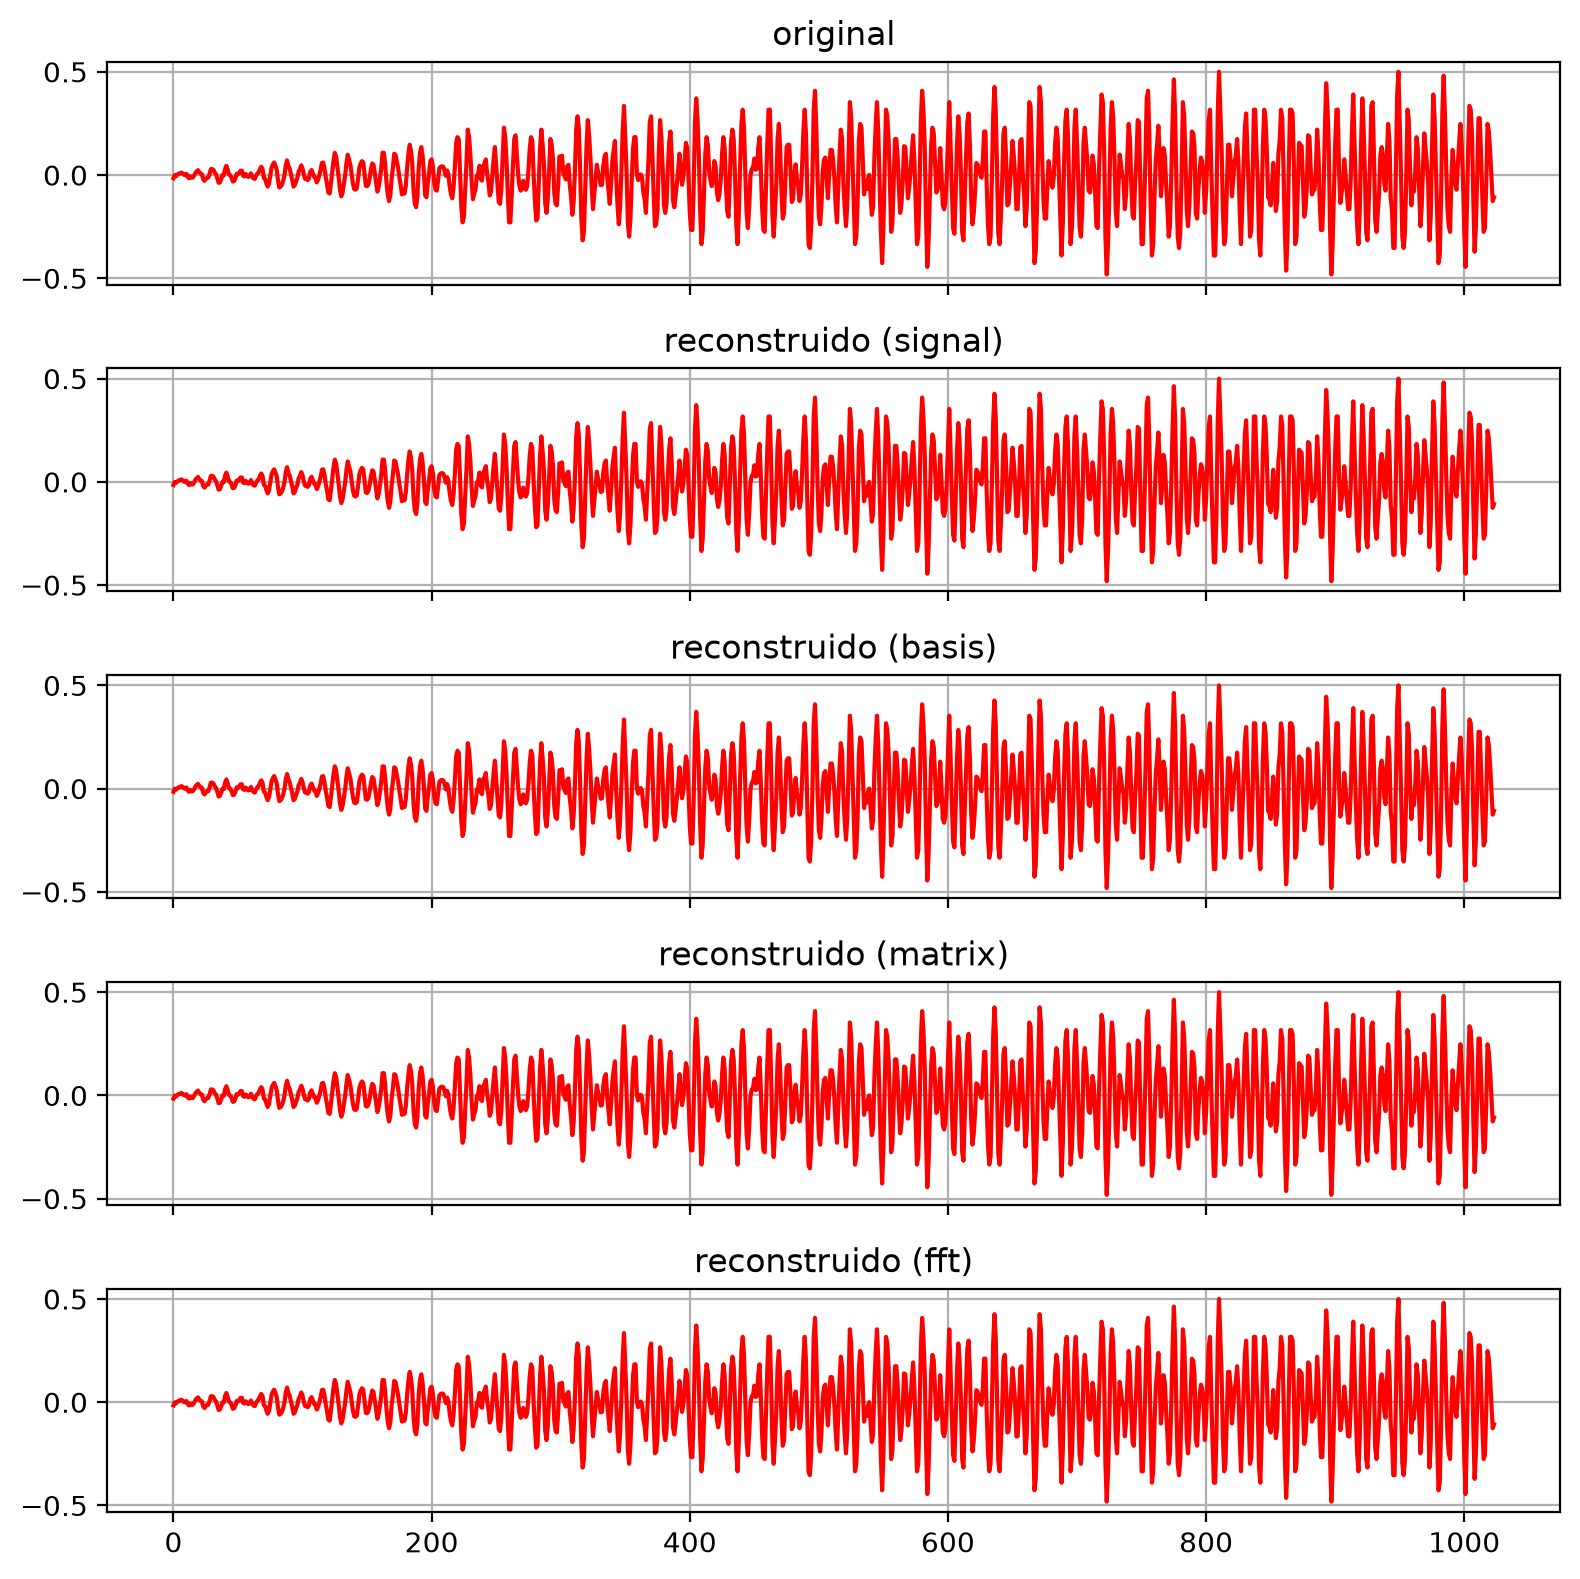

In [25]:
y1 = myIDFT(Y1, 'signal') # sinal reconstruido
y2 = myIDFT(Y2, 'basis') # sinal reconstruido
y3 = myIDFT(Y3, 'matrix') # sinal reconstruido
y4 = myIDFT(Y4, 'fft') # sinal reconstruido

print(y1.dtype)
for name, yk in [('signal', y1), ('basis', y2), ('matrix', y3), ('fft', y4)]:
    print(f"{name:>7}: reconstrucao perfeita? {np.allclose(yk, y)}  erro max = {np.max(np.abs(yk - y)):.2e}")

fig, ax = plt.subplots(5, 1, sharex=True, figsize=(8, 8))
ax[0].plot(y, 'r')
ax[0].set_title('original')
for a, yk, name in zip(ax[1:], [y1, y2, y3, y4], ['signal', 'basis', 'matrix', 'fft']):
    a.plot(yk, 'r')
    a.set_title(f'reconstruido ({name})')
figureFormat(ax, fig, tight=True)
plt.show()

### O som inteiro pela v1

O `train.wav` tem 12880 amostras (1,57 s). Calculamos a análise e a síntese da v1 em blocos de 1024
(o último bloco tem 592 amostras — a v1 funciona com qualquer $N$) e ouvimos o original e o reconstruído.

In [26]:
t0 = time.perf_counter()
x_rec = np.concatenate([myIDFT(myDFT(x[i:i+1024], 'signal'), 'signal') for i in range(0, len(x), 1024)])
print(f"{int(np.ceil(len(x)/1024))} blocos em {time.perf_counter() - t0:.1f} s")
print(f"reconstruido = original? {np.allclose(x_rec, x)}  erro max = {np.max(np.abs(x_rec - x)):.1e}")

print("original:")
play(x, fs)
print("reconstruido pela sintese v1:")
play(x_rec, fs)

13 blocos em 14.6 s
reconstruido = original? True  erro max = 1.2e-13
original:


reconstruido pela sintese v1:


Opa, precisamos apenas da metade da informacao das frequencias *DO ESPECTRO*

Plote a metade do espectro do sinal

> Para um sinal **real**, $X[N-k] = \overline{X[k]}$: o módulo é simétrico em torno de $N/2$ e a fase, antissimétrica.
> A metade $k = 0, \dots, N/2$ já contém tudo. O índice $k$ corresponde à frequência $f_k = k\,\frac{f_s}{N}$,
> e $k = N/2$ é a frequência de Nyquist $f_s/2$.

Simetria conjugada X[N-k] = conj(X[k]): True


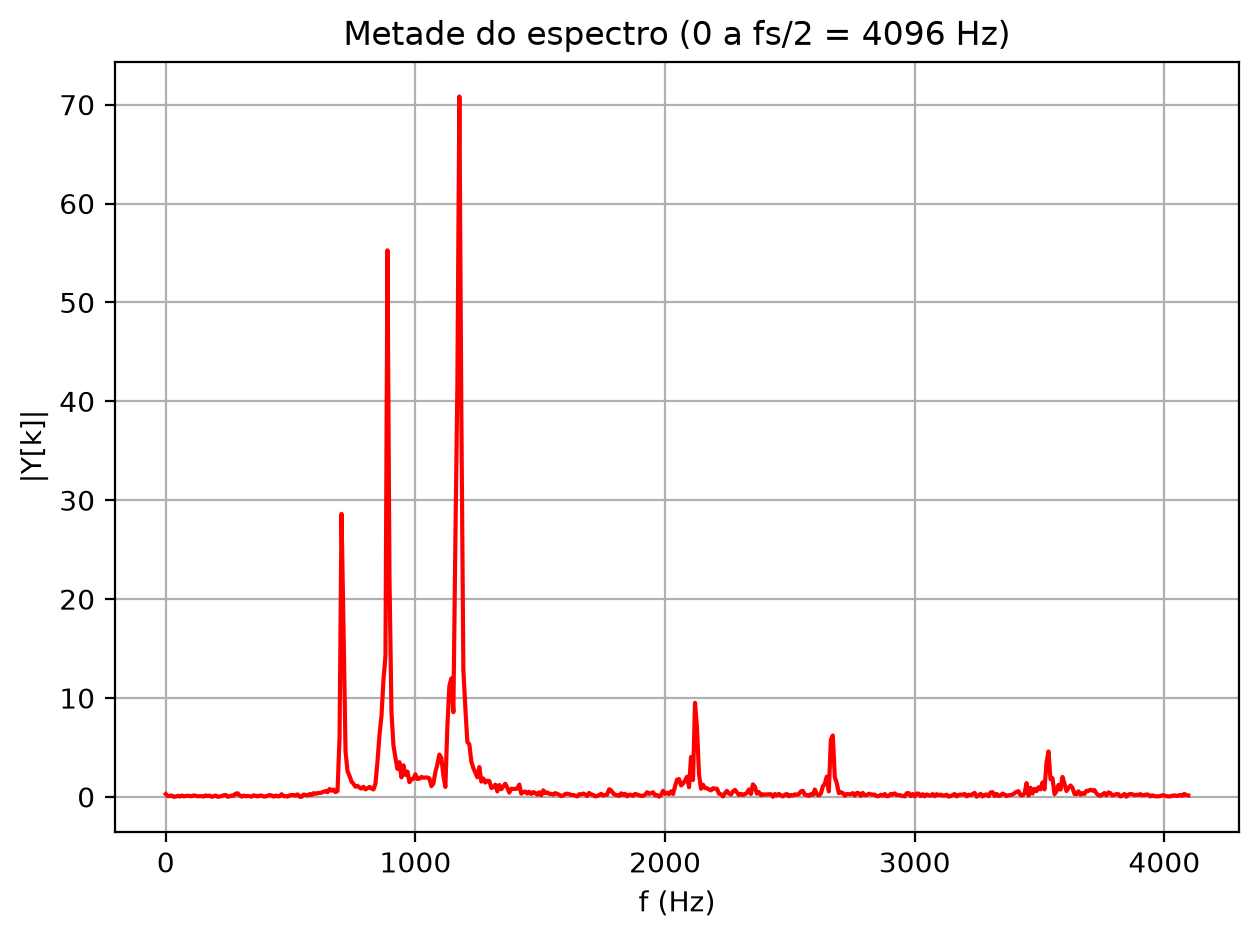

In [27]:
N = len(Y1mag)
print("Simetria conjugada X[N-k] = conj(X[k]):", np.allclose(Y1[1:], np.conj(Y1[1:][::-1])))

k = np.arange(N//2 + 1)
f = k * fs / N # Hz

fig, ax = plt.subplots()
ax.plot(f, Y1mag[:N//2 + 1], 'r')
ax.set_xlabel('f (Hz)')
ax.set_ylabel('|Y[k]|')
ax.set_title(f'Metade do espectro (0 a fs/2 = {fs/2:.0f} Hz)')
figureFormat(ax, fig, tight=True)
plt.show()

### O que o espectro diz sobre o trem

Cada pico é uma frequência presente no som. A resolução em frequência é $\Delta f = f_s/N = 8192/1024 = 8$ Hz:
é a distância entre dois bins vizinhos.

resolucao: 8 Hz por bin

k =   88  ->  f =   704.0 Hz   |Y| = 28.62
k =  111  ->  f =   888.0 Hz   |Y| = 55.27
k =  147  ->  f =  1176.0 Hz   |Y| = 70.82
k =  265  ->  f =  2120.0 Hz   |Y| = 9.51


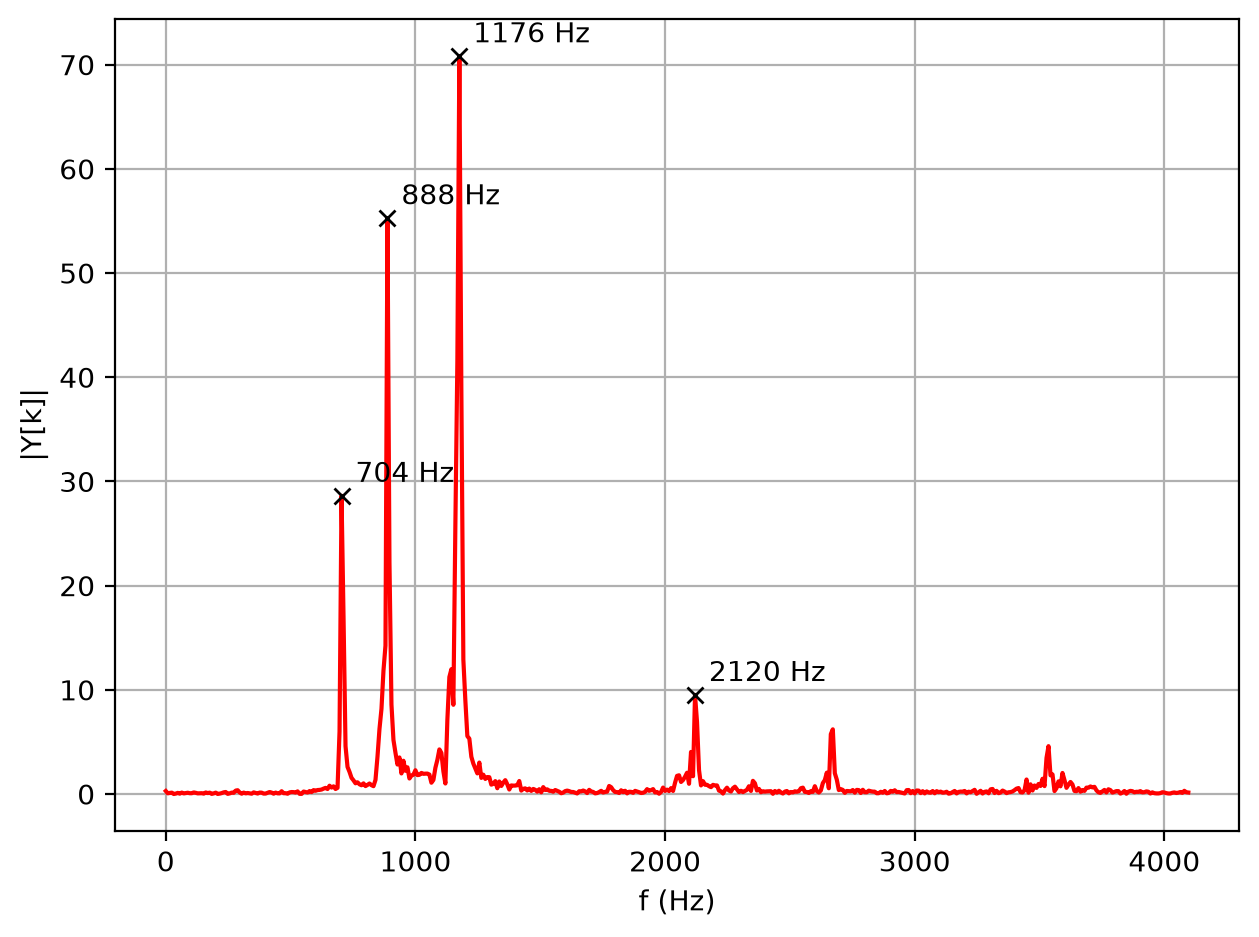

In [28]:
from scipy.signal import find_peaks

meio = Y1mag[:N//2 + 1]
picos, _ = find_peaks(meio, prominence=0.1 * meio.max())
principais = picos[np.argsort(meio[picos])[::-1][:5]]

print(f"resolucao: {fs/N:.0f} Hz por bin\n")
for kp in sorted(principais):
    print(f"k = {kp:4d}  ->  f = {kp*fs/N:7.1f} Hz   |Y| = {meio[kp]:.2f}")

fig, ax = plt.subplots()
ax.plot(f, meio, 'r')
ax.plot(f[principais], meio[principais], 'kx')
for kp in principais:
    ax.annotate(f'{kp*fs/N:.0f} Hz', (f[kp], meio[kp]), textcoords='offset points', xytext=(5, 5))
ax.set_xlabel('f (Hz)')
ax.set_ylabel('|Y[k]|')
figureFormat(ax, fig, tight=True)
plt.show()

### Prova de que a metade basta

Guardando só $X[0], \dots, X[N/2]$ ($N/2 + 1$ números complexos), a outra metade é recuperada por
$X[N-k] = \overline{X[k]}$, e a IDFT devolve o sinal inteiro.

In [29]:
metade = Y4[:N//2 + 1] # so o que guardamos

# Remonta o espectro completo pela simetria conjugada: X[N-k] = conj(X[k]), k = 1 ... N/2-1
completo = np.concatenate([metade, np.conj(metade[1:N//2][::-1])])
y_metade = myIDFT(completo, 'fft')

print(f"guardados: {len(metade)} de {N} coeficientes")
print(f"reconstrucao a partir da metade = y ? {np.allclose(y_metade, y)}  erro max = {np.max(np.abs(y_metade - y)):.1e}")
play(y_metade, fs)

guardados: 513 de 1024 coeficientes
reconstrucao a partir da metade = y ? True  erro max = 3.1e-16


## Plots da DFT para os sinais basicos

O que esperar de cada um:

- **delta** $\delta[n]$: espectro **plano**, $|X[k]| = 1$ — o impulso contém todas as frequências por igual.
- **degrau**: concentrado em $k = 0$ (valor médio alto), decaindo com $k$.
- **exponencial** $a^n u[n]$: passa-baixas, máximo em $k = 0$.
- **oscilação** com período $P$ que divide $N$: só dois picos, em $k = N/P$ e $k = N - N/P$.
- **ruído**: espectro espalhado por todas as frequências, sem estrutura.

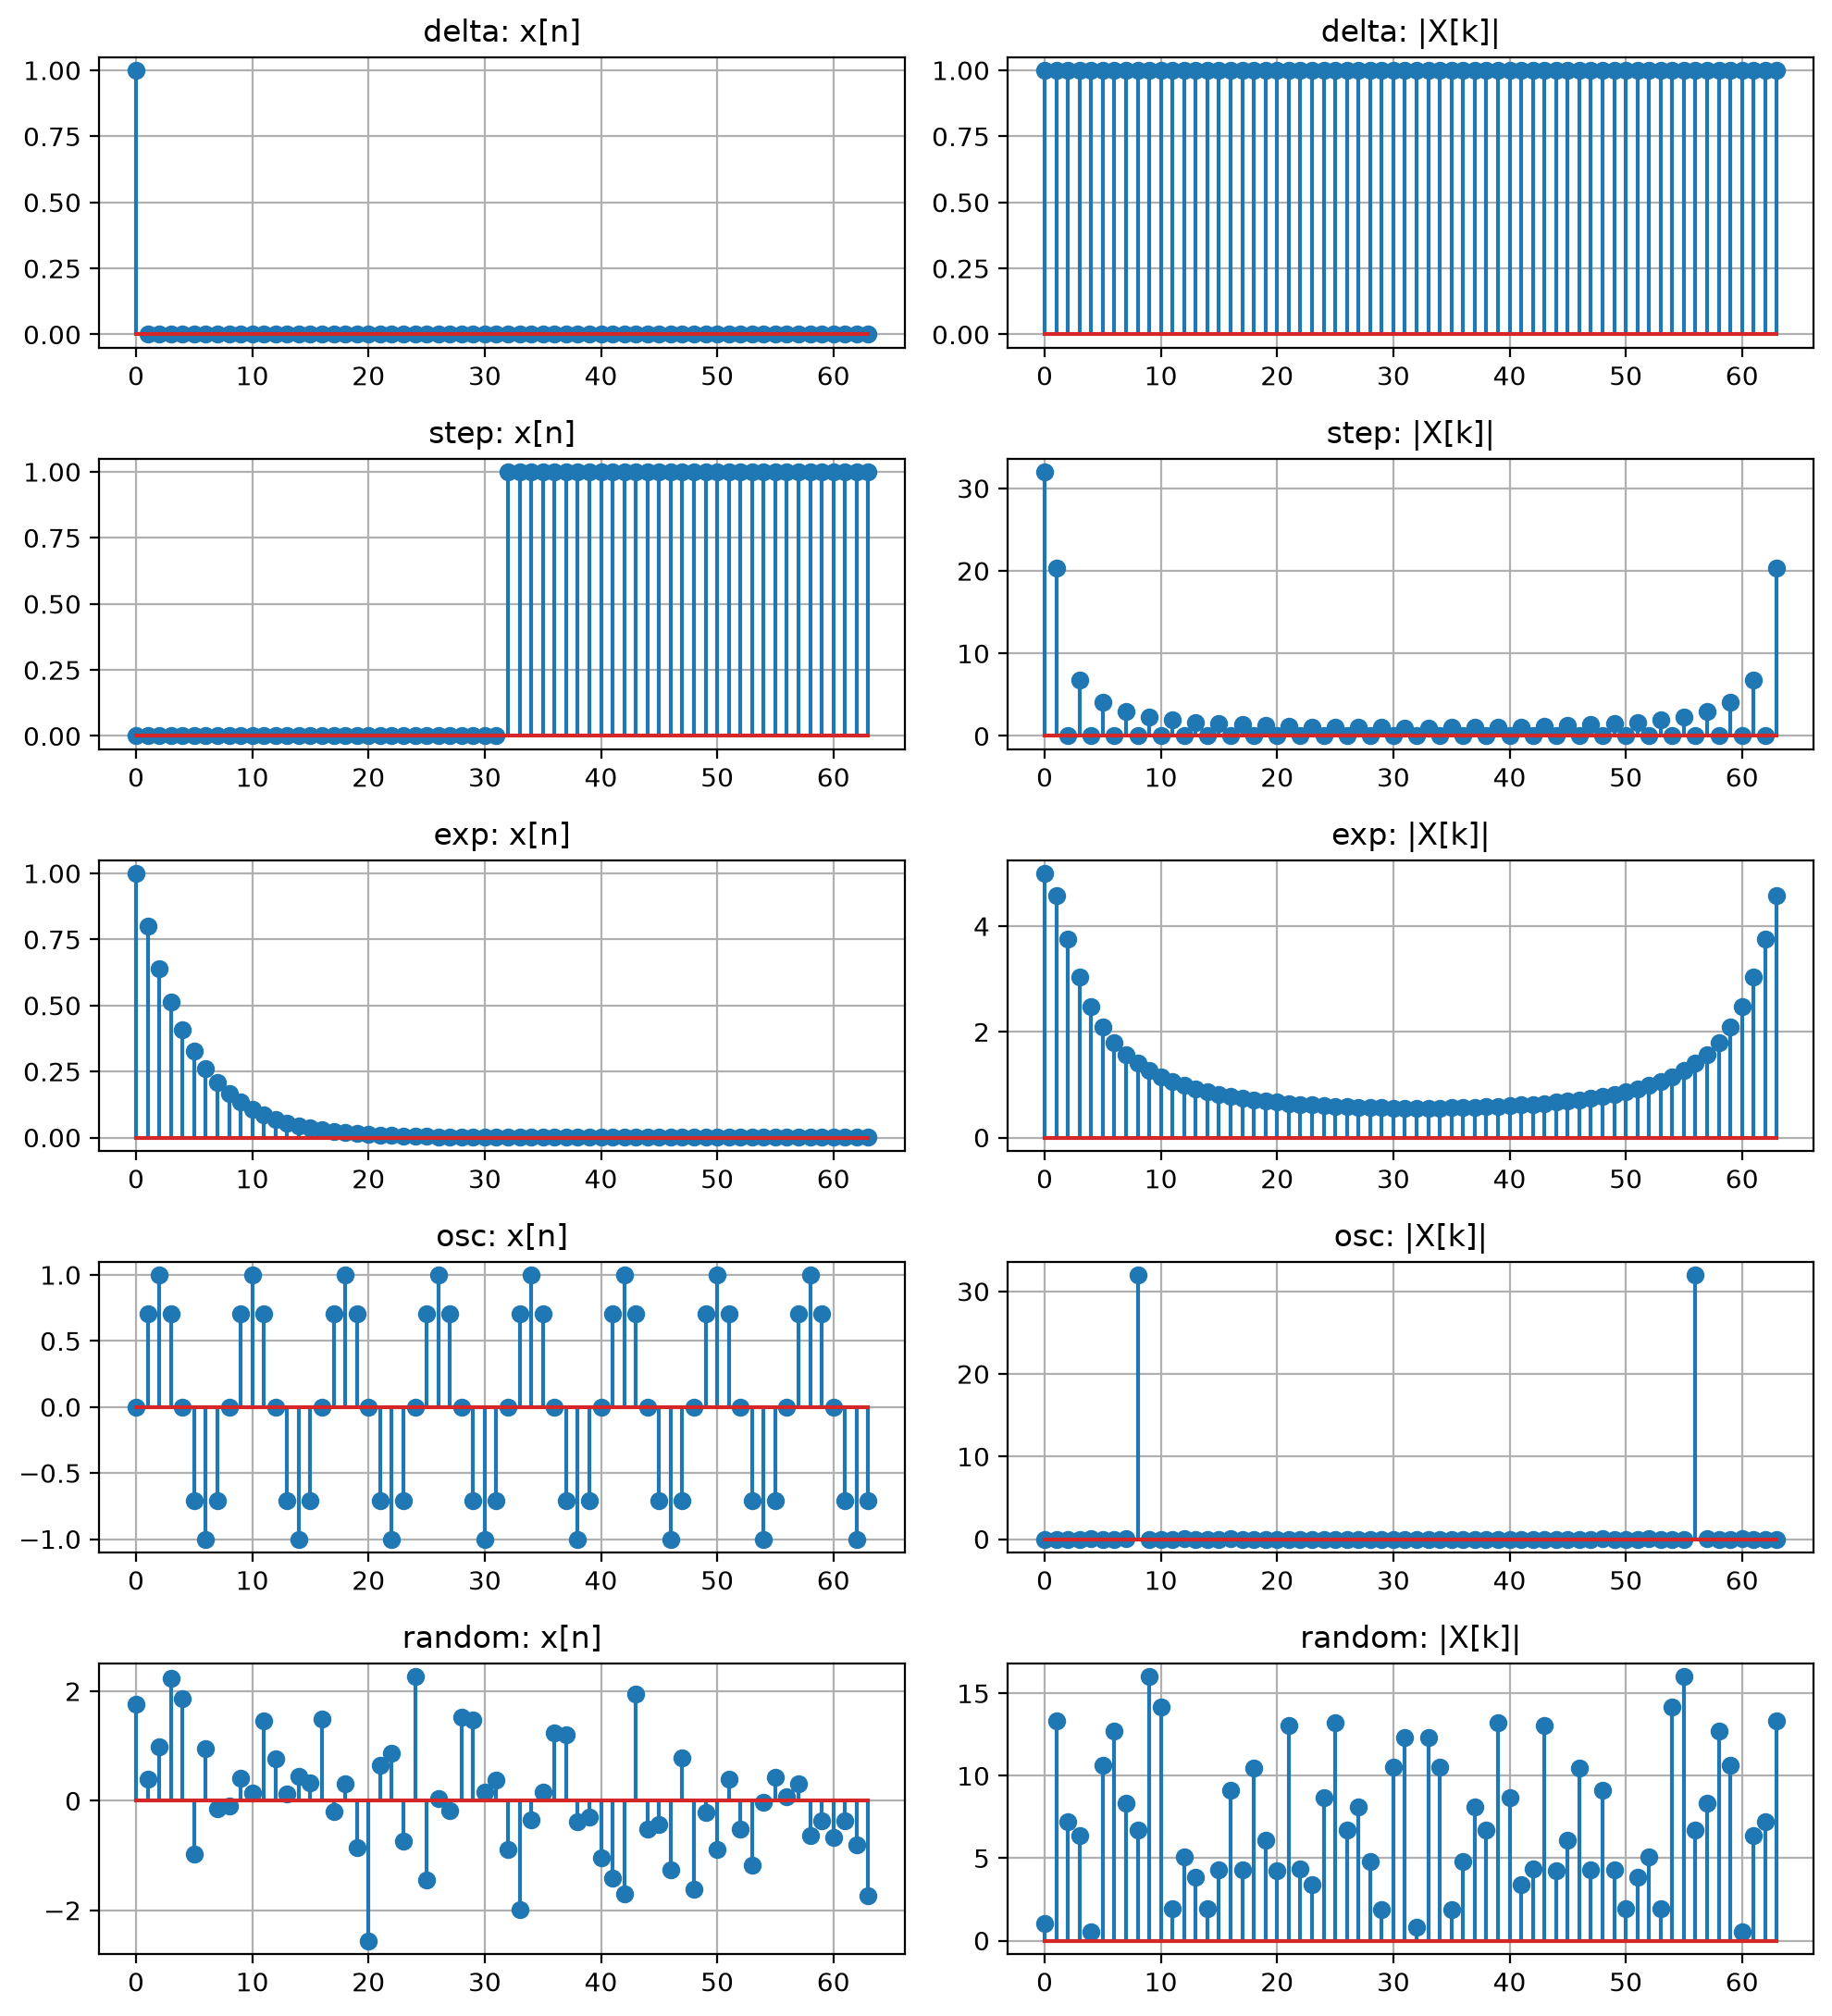

In [30]:
# Plots da DFT para os sinais basicos
N = 64
basicos = [
    ('delta', dict(signal='delta')),
    ('step',  dict(signal='step', params={'k': N//2})),
    ('exp',   dict(signal='exp', params={'a': 0.8})),
    ('osc',   dict(signal='osc', period=8)),
    ('random', dict(signal='random')),
]

np.random.seed(0)
fig, ax = plt.subplots(len(basicos), 2, figsize=(10, 11))
for i, (name, kwargs) in enumerate(basicos):
    s, n = SIGNALgenerate(N=N, **kwargs)
    S = myDFT(s.astype(float), 'fft')
    ax[i, 0].stem(n, s)
    ax[i, 0].set_title(f'{name}: x[n]')
    ax[i, 1].stem(n, COMPLEXmagnitude(S))
    ax[i, 1].set_title(f'{name}: |X[k]|')
figureFormat(ax, fig, tight=True)
plt.show()

### Conferindo as previsões

- **delta**: $X[k] = \sum_n \delta[n]\,e^{-j\frac{2\pi}{N}kn} = 1$ para todo $k$.
- **degrau** de $N/2$ uns: $X[0] = N/2 = 32$ (a soma das amostras), e $X[k] = 0$ para todo $k$ par $\neq 0$ —
  os zeros alternados do gráfico.
- **exponencial**: $X[k] = \dfrac{1 - a^N}{1 - a\,e^{-j\frac{2\pi}{N}k}}$ (soma geométrica), máximo $\frac{1}{1-a} = 5$ em $k = 0$.
- **oscilação** $\sin\left(\frac{2\pi}{8}n\right)$ com $N = 64$: cabem $64/8 = 8$ ciclos, picos em $k = 8$ e $k = 56$,
  de altura $N/2 = 32$.
- **ruído**: pela ortogonalidade, a energia se espalha; em média $|X[k]|^2 \approx N\sigma^2 = 64$, ou $|X[k]| \approx 8$.

In [31]:
N = 64
k = np.arange(N)
a = 0.8

delta, _ = SIGNALgenerate(N=N, signal='delta')
step,  _ = SIGNALgenerate(N=N, signal='step', params={'k': N//2})
expo,  _ = SIGNALgenerate(N=N, signal='exp', params={'a': a})
osc,   _ = SIGNALgenerate(N=N, signal='osc', period=8)

D = myDFT(delta.astype(float))
S = myDFT(step.astype(float))
E = myDFT(expo.astype(float))
O = myDFT(osc.astype(float))

print("delta: |X[k]| = 1 para todo k?          ", np.allclose(COMPLEXmagnitude(D), 1))
print("degrau: X[0] = 32?                       ", np.isclose(S[0], 32))
print("degrau: X[k] = 0 para k par != 0?        ", np.allclose(S[2::2], 0))
print("exp: igual a soma geometrica fechada?     ", np.allclose(E, (1 - a**N) / (1 - a*np.exp(-2j*np.pi*k/N))))
print("osc: picos so em k = 8 e 56, altura 32?   ",
      set(np.flatnonzero(COMPLEXmagnitude(O) > 1e-9)) == {8, 56} and np.isclose(COMPLEXmagnitude(O[8]), 32))

ruido = np.random.default_rng(0).standard_normal((2000, N))
print(f"ruido: media de |X[k]|^2 em 2000 sorteios = {np.mean(np.abs(np.fft.fft(ruido, axis=1))**2):.1f} (previsto N = {N})")

delta: |X[k]| = 1 para todo k?           True
degrau: X[0] = 32?                        True
degrau: X[k] = 0 para k par != 0?         True
exp: igual a soma geometrica fechada?      True
osc: picos so em k = 8 e 56, altura 32?    True
ruido: media de |X[k]|^2 em 2000 sorteios = 64.2 (previsto N = 64)


## Um sinal com duas frequências: 900 Hz + 1200 Hz

    x(t) = sen(2π·900·t) + sen(2π·1200·t)

No tempo, as duas senoides se misturam e não dá para ver quais frequências estão ali. Na DFT, cada uma vira um pico.

**Escolha dos parâmetros.** Para as quatro versões funcionarem, **N tem de ser potência de 2** (por causa da FFT radix-2). Com **fs = 9600 Hz** e **N = 1024**, a resolução é **Δf = fs/N = 9,375 Hz**, e as duas frequências caem **exatamente** em bins inteiros:

    k = f / Δf   →   900 / 9,375 = 96     e     1200 / 9,375 = 128

Cada senoide de amplitude A vira um pico de altura **A·N/2 = 512** em k (e o espelho em N − k). Se f / Δf **não** fosse inteiro, a energia vazaria para os bins vizinhos (**vazamento espectral**).

> Ao trocar as frequências, confira se f / Δf continua inteiro. Exemplo: com fs = 9600 e N = 2048, Δf = 4,6875 Hz: 2400 Hz cai no bin 512 (exato), mas 800 Hz cai em 170,67 e vaza. Para 800 + 2400 Hz saírem limpos, use fs = 8192 e N = 2048 (Δf = 4 Hz, bins 200 e 600).

In [32]:
fs2 = 9600        # Hz (> 2 x 1200: Nyquist ok)
f1, f2 = 800, 2400
N = 2048          # potencia de 2 -> as quatro versoes funcionam

t  = np.arange(fs2) / fs2           # 1 s de sinal, para ouvir
s1 = np.sin(2 * np.pi * f1 * t)
s2 = np.sin(2 * np.pi * f2 * t)
s  = s1 + s2

print(f"{f1} Hz:")
play(s1, fs2)
print(f"{f2} Hz:")
play(s2, fs2)
print(f"{f1} Hz + {f2} Hz:")
play(s, fs2)

800 Hz:


2400 Hz:


800 Hz + 2400 Hz:


In [33]:
S = {v: myDFT(s[:N], v) for v in ['signal', 'basis', 'matrix', 'fft', 'numpy']}
print("as quatro versoes concordam com o numpy?", all(np.allclose(S[v], S['numpy']) for v in S))

k  = np.arange(N//2 + 1)
fk = k * fs2 / N                     # frequencia de cada bin (Hz)
mag = COMPLEXmagnitude(S['signal'])[:N//2 + 1]

achadas = k[mag > 0.5 * mag.max()]
print(f"\nresolucao: {fs2/N} Hz por bin")
for kk in achadas:
    print(f"k = {kk:3d}  ->  f = k fs/N = {kk*fs2/N:6.0f} Hz   |X[k]| = {mag[kk]:.1f}   amplitude = 2|X|/N = {2*mag[kk]/N:.2f}")
print(f"maior |X[k]| fora desses bins: {np.delete(mag, achadas).max():.1e}")

as quatro versoes concordam com o numpy? True

resolucao: 4.6875 Hz por bin
k = 171  ->  f = k fs/N =    802 Hz   |X[k]| = 846.1   amplitude = 2|X|/N = 0.83
k = 512  ->  f = k fs/N =   2400 Hz   |X[k]| = 1024.5   amplitude = 2|X|/N = 1.00
maior |X[k]| fora desses bins: 4.2e+02


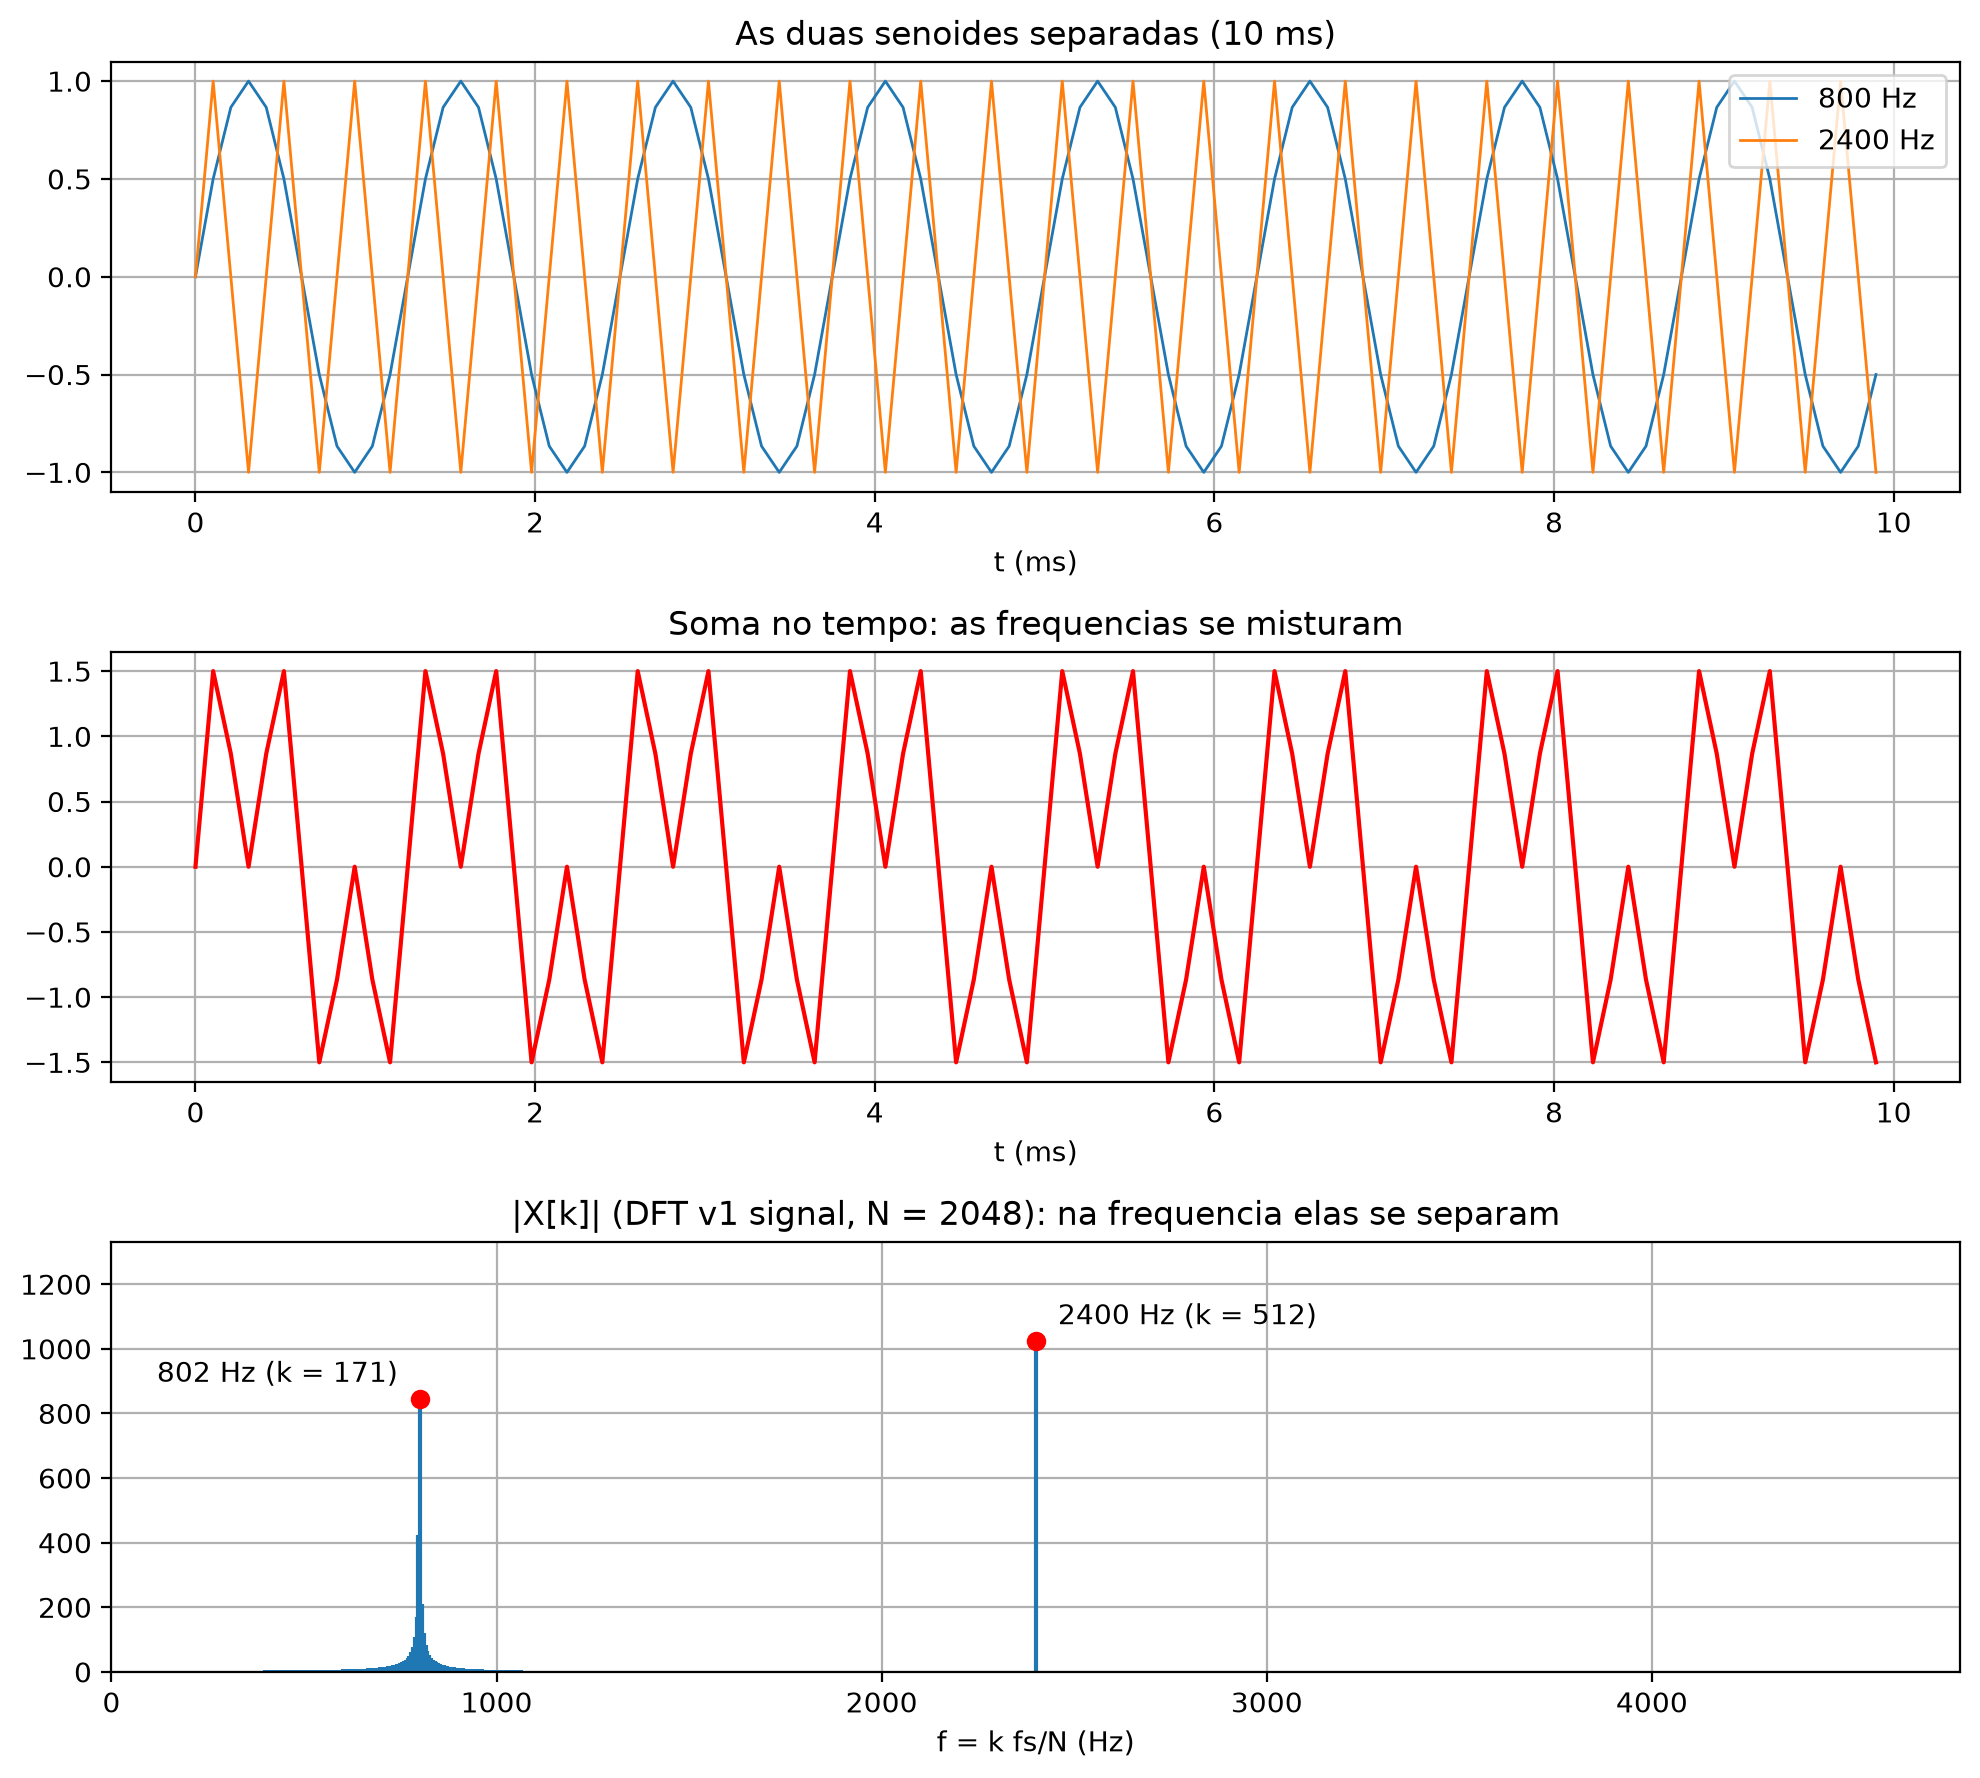

In [34]:
zoom = t < 0.01 # 10 ms

fig, ax = plt.subplots(3, 1, figsize=(10, 9))
ax[0].plot(t[zoom] * 1e3, s1[zoom], color='tab:blue', linewidth=1, label=f'{f1} Hz')
ax[0].plot(t[zoom] * 1e3, s2[zoom], color='tab:orange', linewidth=1, label=f'{f2} Hz')
ax[0].set_title('As duas senoides separadas (10 ms)')
ax[0].set_xlabel('t (ms)')
ax[0].legend(loc='upper right')

ax[1].plot(t[zoom] * 1e3, s[zoom], 'r')
ax[1].set_title('Soma no tempo: as frequencias se misturam')
ax[1].set_xlabel('t (ms)')

ax[2].stem(fk, mag, basefmt=' ', markerfmt=' ')
ax[2].plot(fk[achadas], mag[achadas], 'ro')
for i, kk in enumerate(achadas): # rotulos para lados opostos, sem sobrepor
    ax[2].annotate(f'{kk*fs2/N:.0f} Hz (k = {kk})', (fk[kk], mag[kk]),
                   textcoords='offset points', xytext=(-8 if i == 0 else 8, 6),
                   ha='right' if i == 0 else 'left')
ax[2].set_xlim([0, fs2 / 2])
ax[2].set_ylim([0, 1.3 * mag.max()])
ax[2].set_title(f'|X[k]| (DFT v1 signal, N = {N}): na frequencia elas se separam')
ax[2].set_xlabel('f = k fs/N (Hz)')
figureFormat(ax, fig, tight=True)
plt.show()

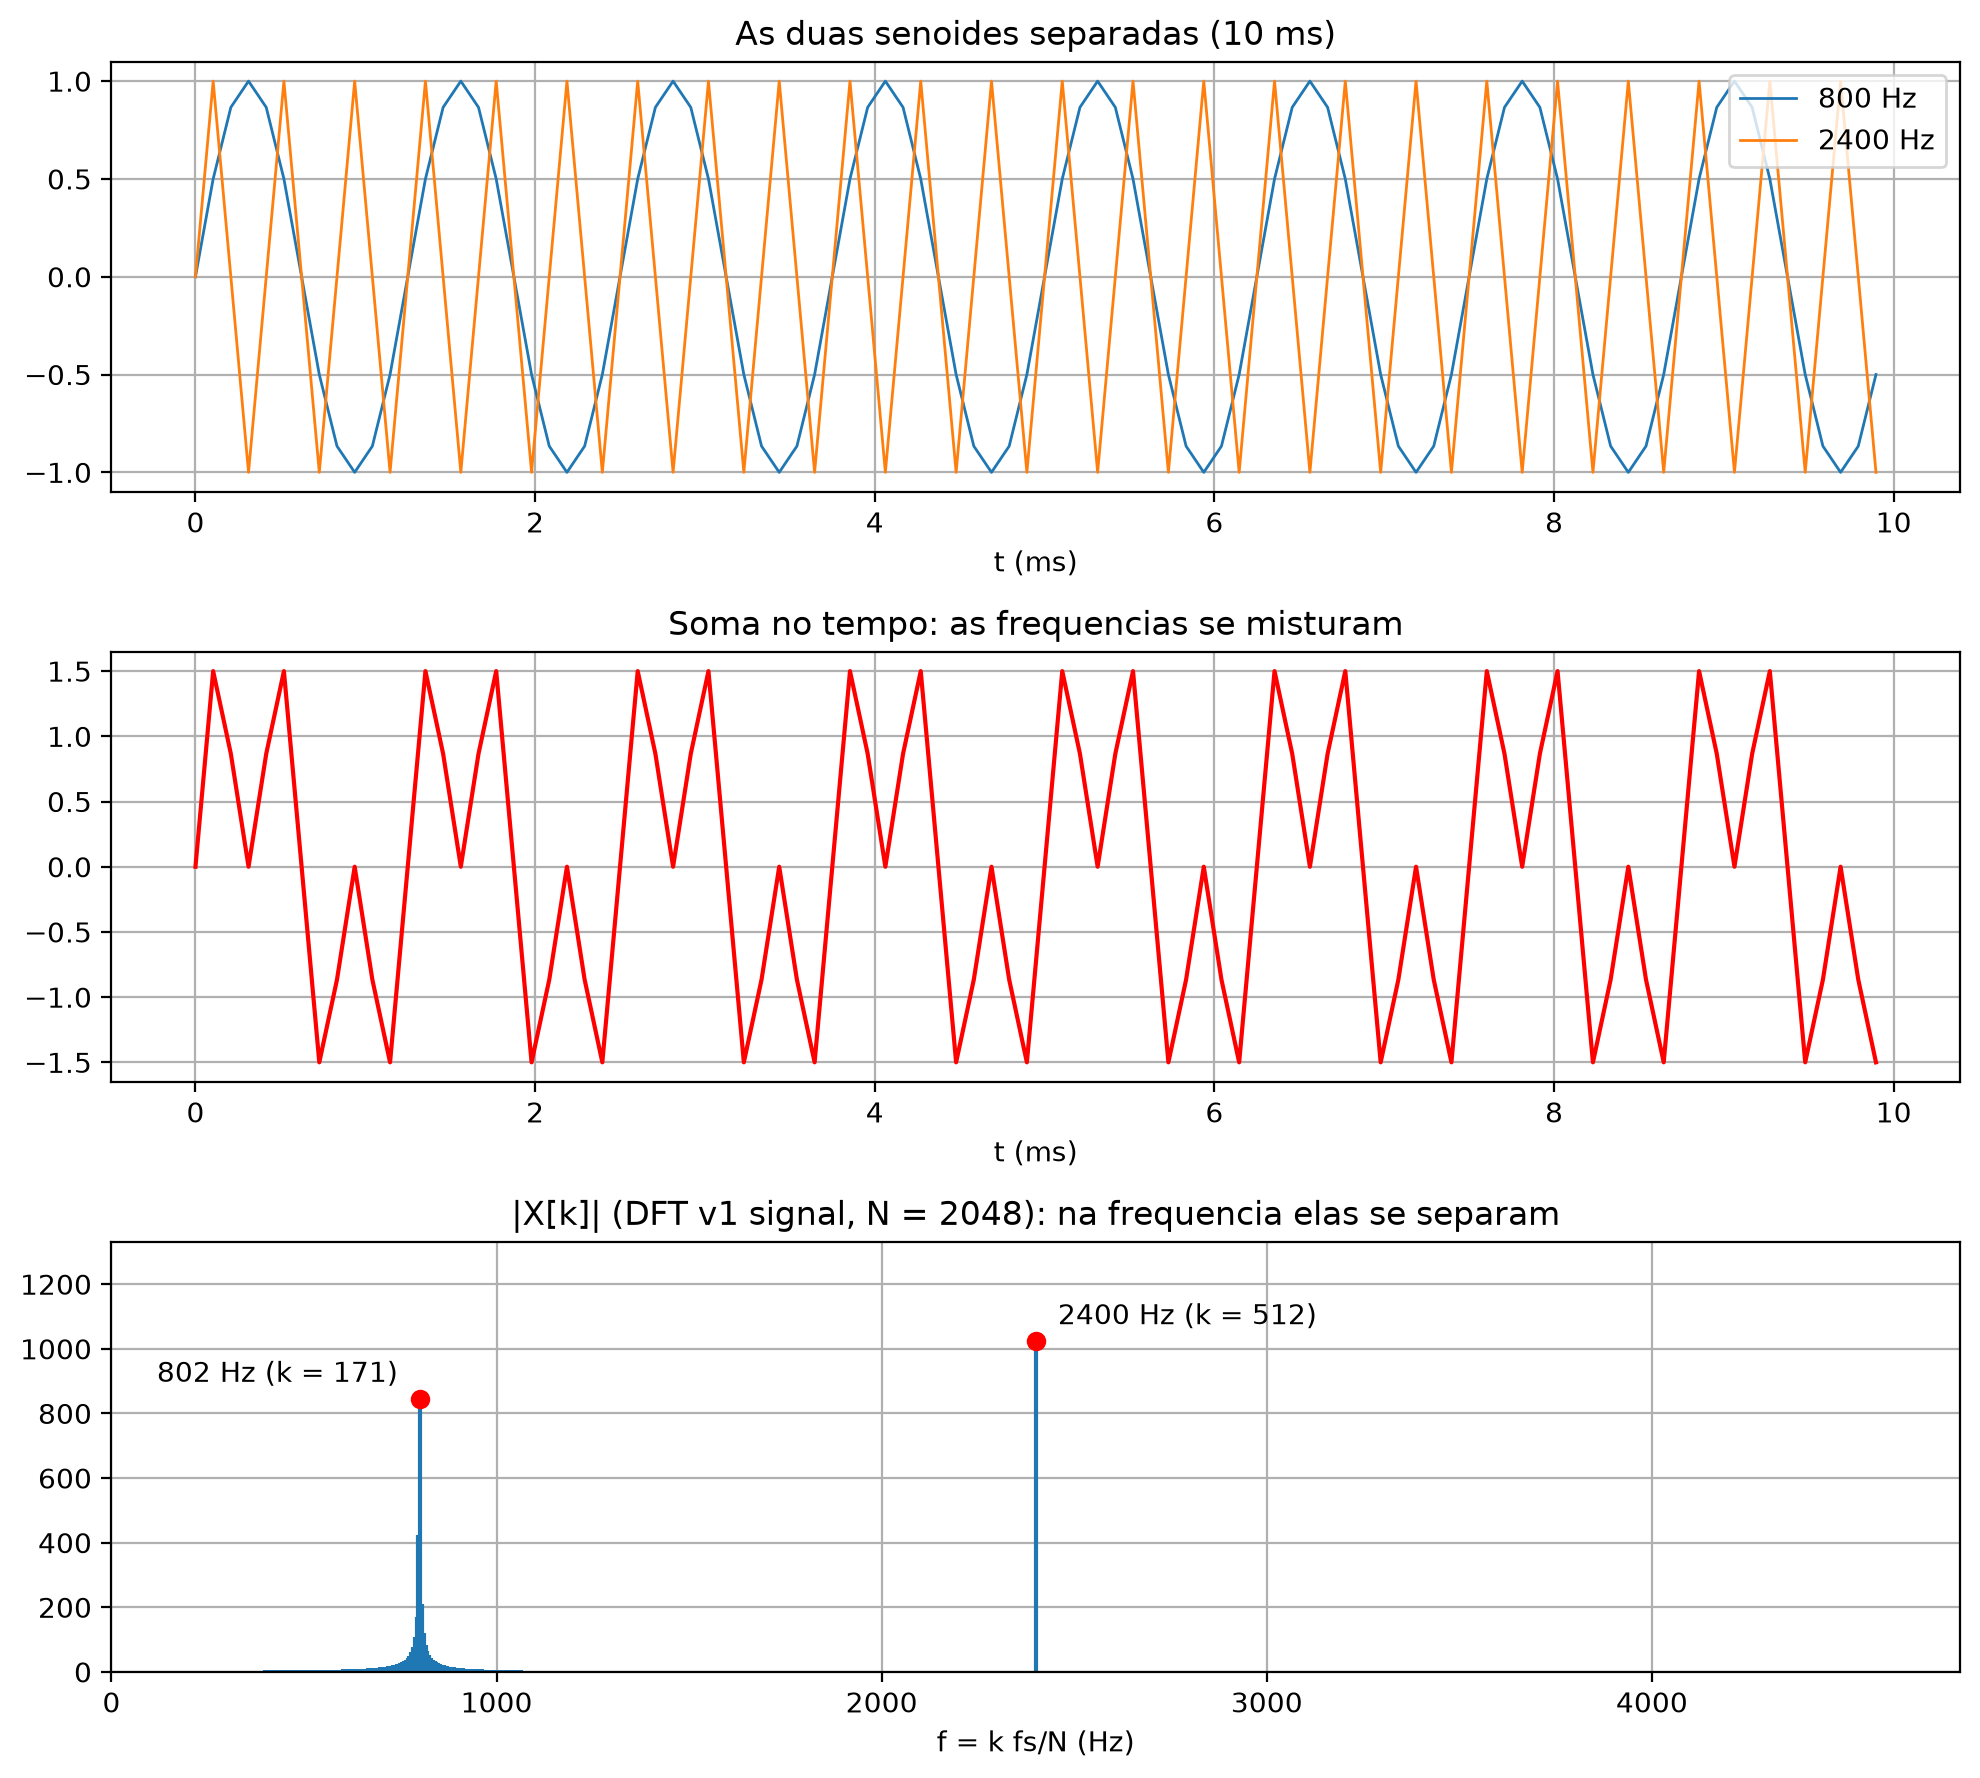

In [35]:
zoom = t < 0.01 # 10 ms

fig, ax = plt.subplots(3, 1, figsize=(10, 9))
ax[0].plot(t[zoom] * 1e3, s1[zoom], color='tab:blue', linewidth=1, label=f'{f1} Hz')
ax[0].plot(t[zoom] * 1e3, s2[zoom], color='tab:orange', linewidth=1, label=f'{f2} Hz')
ax[0].set_title('As duas senoides separadas (10 ms)')
ax[0].set_xlabel('t (ms)')
ax[0].legend(loc='upper right')

ax[1].plot(t[zoom] * 1e3, s[zoom], 'r')
ax[1].set_title('Soma no tempo: as frequencias se misturam')
ax[1].set_xlabel('t (ms)')

ax[2].stem(fk, mag, basefmt=' ', markerfmt=' ')
ax[2].plot(fk[achadas], mag[achadas], 'ro')
for i, kk in enumerate(achadas): # rotulos para lados opostos, sem sobrepor
    ax[2].annotate(f'{kk*fs2/N:.0f} Hz (k = {kk})', (fk[kk], mag[kk]),
                   textcoords='offset points', xytext=(-8 if i == 0 else 8, 6),
                   ha='right' if i == 0 else 'left')
ax[2].set_xlim([0, fs2 / 2])
ax[2].set_ylim([0, 1.3 * mag.max()])
ax[2].set_title(f'|X[k]| (DFT v1 signal, N = {N}): na frequencia elas se separam')
ax[2].set_xlabel('f = k fs/N (Hz)')
figureFormat(ax, fig, tight=True)
plt.show()

## Remover um som com a DFT: violão + guitarra → só o violão

**Tarefa:** dois sons tocam juntos, e um deles é indesejado. Exemplo: a gravação pegou um **violão** e uma **guitarra** ao mesmo tempo, e se quer **só o violão**. Cada instrumento é representado por um sinal oscilatório:

| instrumento | frequência | como é gerado | papel |
|---|---|---|---|
| violão | 900 Hz | `np.sin` direto | o som que fica |
| guitarra | 1200 Hz | primitiva `osc` (`SIGNALgenerate`) | o som que sai |

**Ideia:** no tempo os dois estão misturados em cada amostra e não dá para separar. Na frequência, cada um é um pico num bin diferente. Então:

1. **análise** — DFT da mistura: `X = myDFT(x)`;
2. **remover** — zerar o bin da guitarra **e o seu espelho** (`X[k] = 0` e `X[N−k] = 0`);
3. **síntese** — IDFT de volta ao tempo: `y = myIDFT(X)`.

Isso é um **filtro**: um sistema que deixa passar umas frequências e bloqueia outras. A saída é o violão **puro**.

**Parâmetros:** fs = 8192 Hz e N = 8192 amostras (1 s de som). A resolução é Δf = fs/N = **1 Hz**, então 900 Hz cai no bin 900 e 1200 Hz no bin 1200, exatos. N = 8192 = 2¹³ é potência de 2, então a versão `fft` processa o segundo inteiro de uma vez.

In [36]:
fs3 = 8192          # Hz (> 2 x 1200: Nyquist ok)
N3  = fs3           # 1 s de sinal; 8192 = 2^13 -> a versao 'fft' funciona
df3 = fs3 / N3      # resolucao: 1 Hz por bin

f_violao, f_guitarra = 900, 1200

n3 = np.arange(N3)
violao      = np.sin(2 * np.pi * f_violao * n3 / fs3)                  # o som que fica
guitarra, _ = SIGNALgenerate(N3, 'osc', period=fs3 / f_guitarra)      # o som que sai (osc)
mistura     = violao + guitarra                                       # a gravacao com os dois

print(f"violao ({f_violao} Hz):")
play(violao, fs3)
print(f"guitarra ({f_guitarra} Hz):")
play(guitarra, fs3)
print("mistura (violao + guitarra):")
play(mistura, fs3)

violao (900 Hz):


guitarra (1200 Hz):


mistura (violao + guitarra):


In [37]:
# 1. Analise: do tempo para a frequencia
X_mistura = myDFT(mistura, 'fft')

# 2. Remover a guitarra: zera o bin dela E o espelho
k_guitarra = int(round(f_guitarra / df3))       # 1200 / 1 = bin 1200
X_limpo = X_mistura.copy()
X_limpo[k_guitarra]      = 0                    # frequencia positiva
X_limpo[N3 - k_guitarra] = 0                    # espelho (frequencia negativa)

# 3. Sintese: de volta ao tempo
saida = myIDFT(X_limpo, 'fft')

print(f"bins zerados: k = {k_guitarra} e k = {N3 - k_guitarra}")
print(f"saida = violao puro?  {np.allclose(saida, violao)}   (erro max {np.max(np.abs(saida - violao)):.1e})")
print("saida (so o violao):")
play(saida, fs3)

bins zerados: k = 1200 e k = 6992
saida = violao puro?  True   (erro max 6.3e-13)
saida (so o violao):


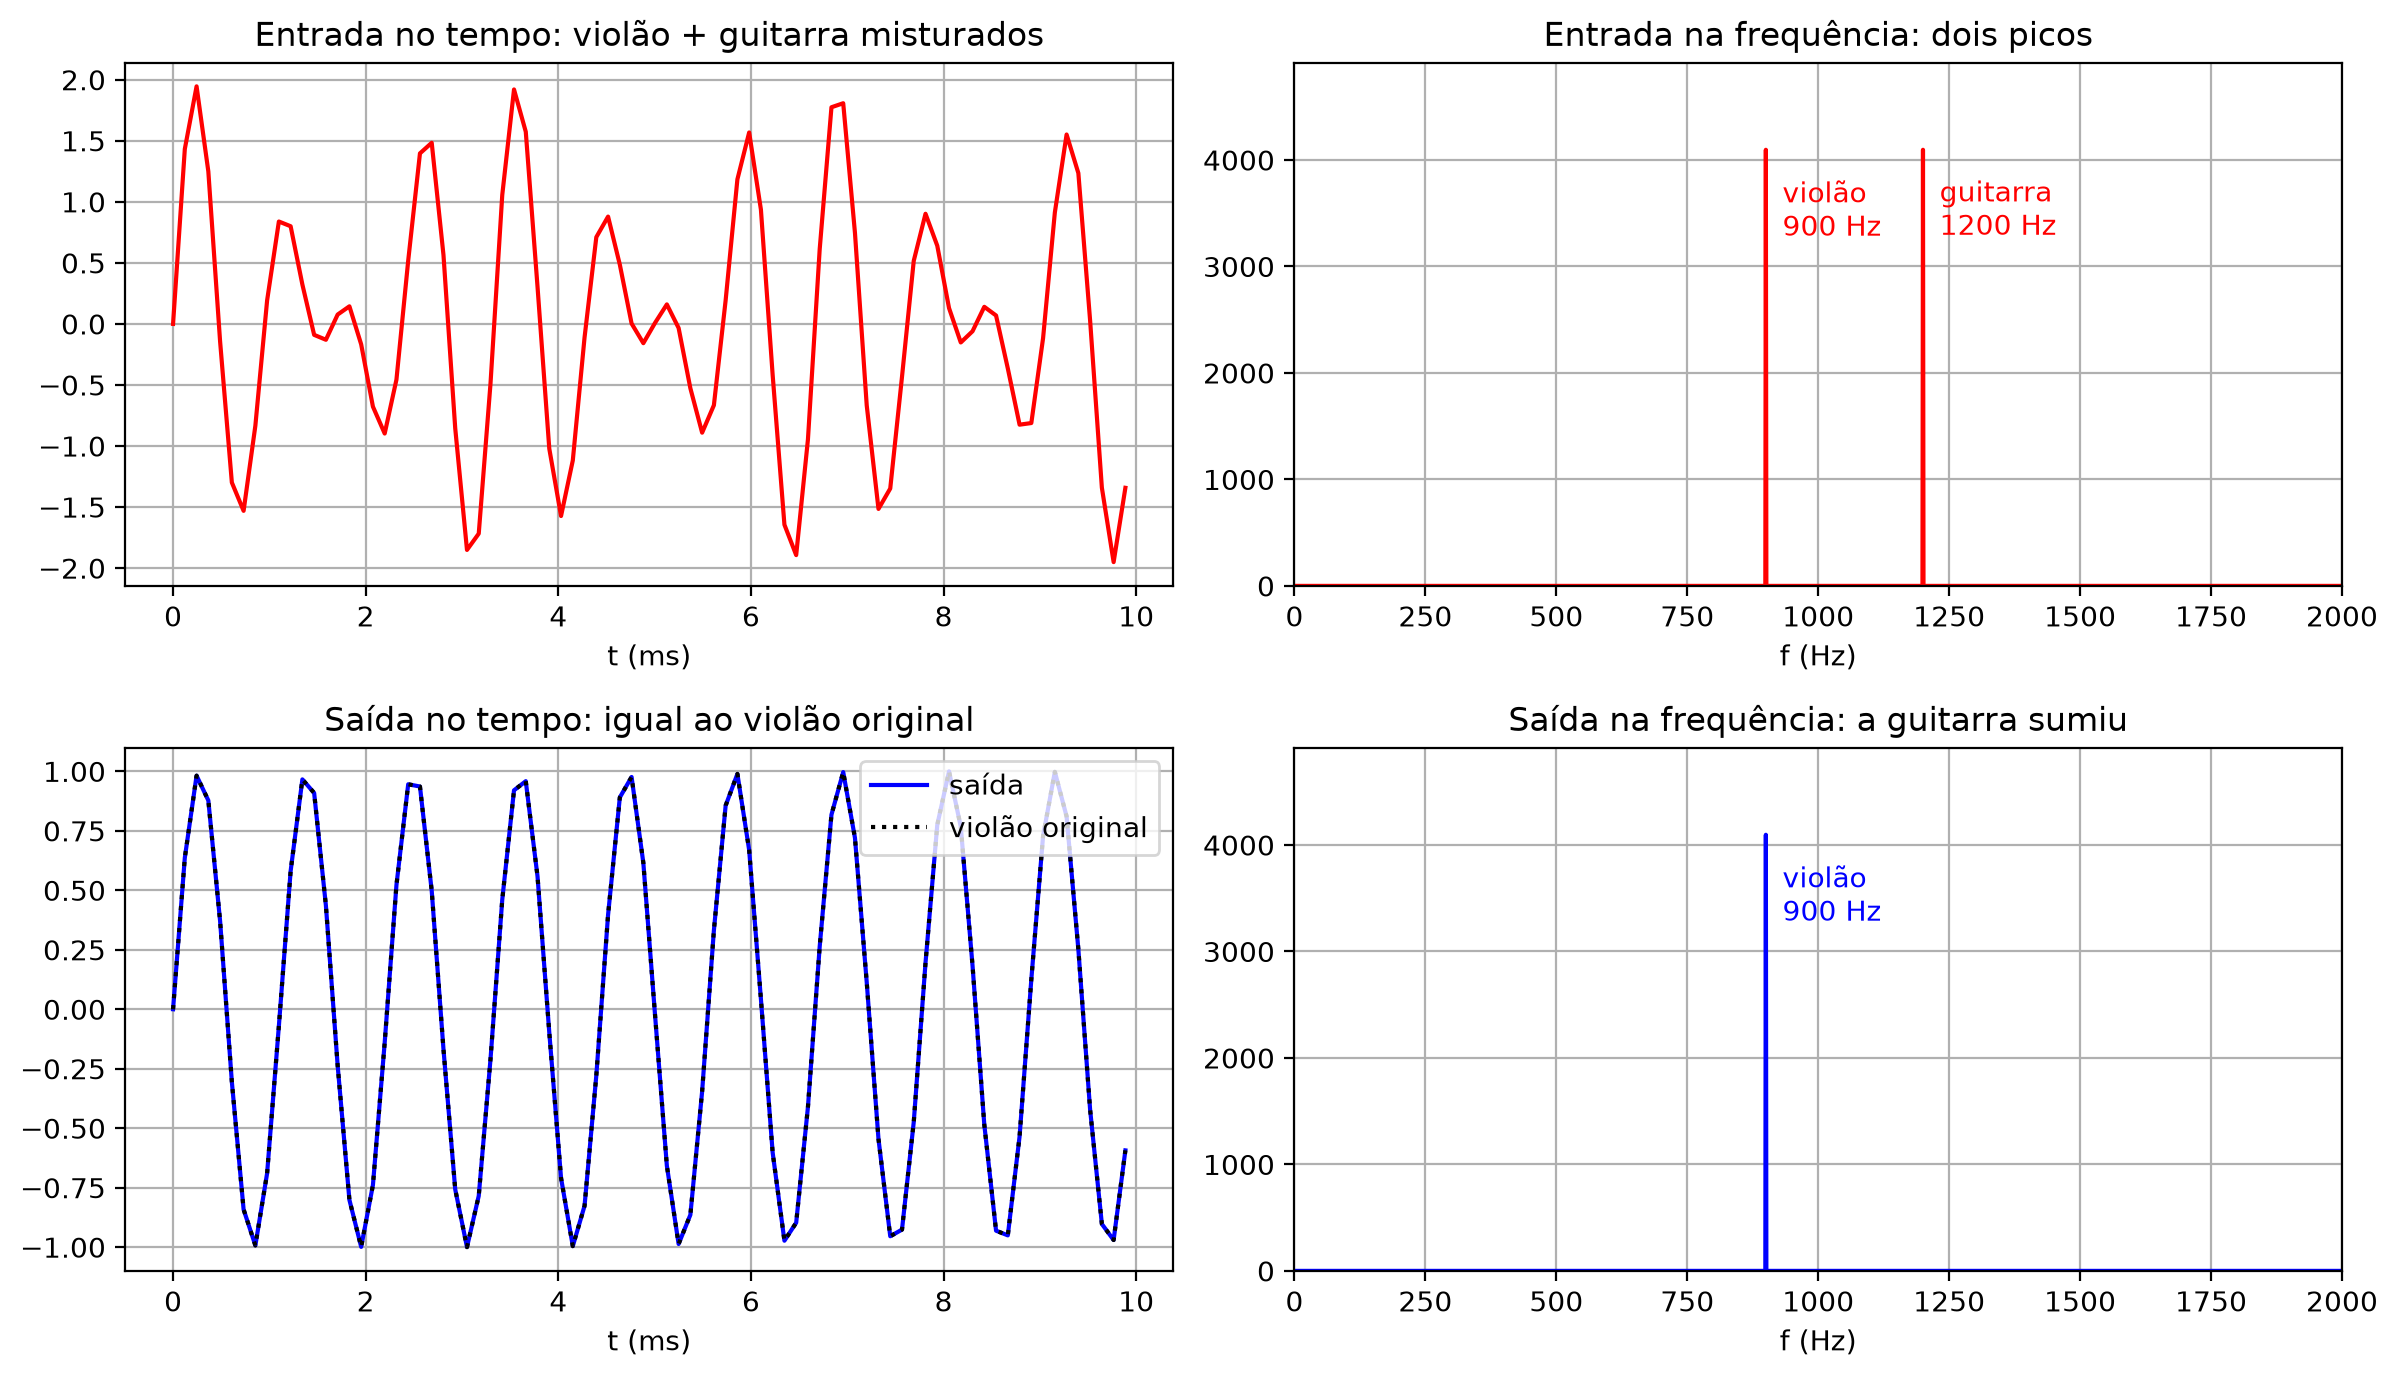

In [38]:
meio = N3 // 2 + 1
fk3  = np.arange(meio) * df3                                   # Hz de cada bin
mag_mistura = COMPLEXmagnitude(X_mistura[:meio])
mag_saida   = COMPLEXmagnitude(myDFT(saida, 'fft')[:meio])     # DFT da SAIDA, medida de novo
zoom3 = n3 < fs3 * 0.01                                        # 10 ms

fig, ax = plt.subplots(2, 2, figsize=(12, 7))
ax[0, 0].plot(n3[zoom3] / fs3 * 1e3, mistura[zoom3], 'r')
ax[0, 0].set_title('Entrada no tempo: violão + guitarra misturados')
ax[0, 1].plot(fk3, mag_mistura, 'r')
ax[0, 1].set_title('Entrada na frequência: dois picos')
ax[1, 0].plot(n3[zoom3] / fs3 * 1e3, saida[zoom3], 'b', label='saída')
ax[1, 0].plot(n3[zoom3] / fs3 * 1e3, violao[zoom3], 'k:', label='violão original')
ax[1, 0].set_title('Saída no tempo: igual ao violão original')
ax[1, 0].legend(loc='upper right')
ax[1, 1].plot(fk3, mag_saida, 'b')
ax[1, 1].set_title('Saída na frequência: a guitarra sumiu')
for a in ax[:, 0]:
    a.set_xlabel('t (ms)')
for a in ax[:, 1]:
    a.set_xlabel('f (Hz)')
    a.set_xlim([0, 2000])
    a.set_ylim([0, 1.2 * mag_mistura.max()])
nomes = {f_violao: 'violão', f_guitarra: 'guitarra'}
for i, (mag, cor) in enumerate([(mag_mistura, 'r'), (mag_saida, 'b')]):
    for kk in np.flatnonzero(mag > 0.5 * mag.max()):
        ax[i, 1].annotate(f'{nomes[int(fk3[kk])]}\n{fk3[kk]:.0f} Hz', (fk3[kk], mag[kk]),
                          textcoords='offset points', xytext=(6, -10), ha='left', va='top', color=cor)
figureFormat(ax, fig, tight=True)
plt.show()

### Por que zerar **dois** bins (k e N − k)?

Um seno real é a soma de **duas** setas girando em sentidos opostos:

    sen(ωn) = ( e^(jωn) − e^(−jωn) ) / 2j

A DFT mostra cada seta num bin: a que gira para um lado em **k**, a que gira para o outro em **N − k** (as "frequências negativas" — o espelho). Se zerar só o bin k, sobra a outra seta sozinha: a saída fica **complexa** e a guitarra continua lá com **metade** da amplitude. Medindo:

In [39]:
X_errado = X_mistura.copy()
X_errado[k_guitarra] = 0                            # so o bin k, esquecendo o espelho
s_errado = np.fft.ifft(X_errado)                    # IDFT sem descartar a parte imaginaria

resto = s_errado.real - violao                      # o que sobrou alem do violao
print(f"parte imaginaria da saida: ate {np.max(np.abs(s_errado.imag)):.2f}  (deveria ser 0)")
print(f"a guitarra continua na parte real, com amplitude {np.max(np.abs(resto)):.2f}  (era 1.00)")

parte imaginaria da saida: ate 0.50  (deveria ser 0)
a guitarra continua na parte real, com amplitude 0.50  (era 1.00)


### Versão geral: remover uma faixa de frequências

Quando a frequência **não** cai num bin exato (vazamento espectral), a energia dela está espalhada pelos bins vizinhos, e zerar um bin só não basta. A função abaixo zera **todos os bins a até `largura` Hz** da frequência indesejada, nos dois lados do espectro de uma vez. O truque é `min(k, N − k)`, que dá a frequência positiva de cada bin, já com o espelho dobrado.

> **E um violão e uma guitarra de verdade?** Um instrumento real não é uma senoide só: a nota tem a **fundamental** e os **harmônicos** (2×, 3×, 4× a fundamental — é o timbre, visto no le04). Para remover a guitarra de verdade, seria preciso zerar a fundamental **e todos os harmônicos dela**, chamando a função para cada um. E onde um harmônico da guitarra coincide com um do violão, remover um apaga um pedaço do outro: é por isso que separar instrumentos reais é um problema difícil.

In [40]:
def apagar_frequencia(x, fs, f_apagar, largura=0.0, version='fft'):
    '''
    Remove de x as frequencias a ate 'largura' Hz de f_apagar (filtro na frequencia).

    x        : sinal de entrada (real)
    fs       : frequencia de amostragem (Hz)
    f_apagar : frequencia a remover (Hz)
    largura  : meia-largura da faixa removida (Hz); 0 = so o bin mais proximo
    '''
    N  = len(x)
    X  = myDFT(x, version)
    k  = np.arange(N)
    fk = np.minimum(k, N - k) * fs / N           # frequencia de cada bin, espelho incluido
    faixa = np.abs(fk - f_apagar) <= max(largura, fs / N / 2)
    X[faixa] = 0
    return myIDFT(X, version)

# O mesmo resultado de antes, agora com a funcao -- e o caminho inverso, para comparar
so_violao   = apagar_frequencia(mistura, fs3, f_guitarra)
so_guitarra = apagar_frequencia(mistura, fs3, f_violao)
print("remover a guitarra -> sobra o violao puro?  ", np.allclose(so_violao, violao))
print("remover o violao   -> sobra a guitarra pura?", np.allclose(so_guitarra, guitarra))
print("so a guitarra:")
play(so_guitarra, fs3)

remover a guitarra -> sobra o violao puro?   True
remover o violao   -> sobra a guitarra pura? True
so a guitarra:


In [41]:
print(xmag)

NameError: name 'xmag' is not defined